# NOTEBOOK 3: VGG-UNet TRANSFER LEARNING

## Cellule 1 :                                                    Optimisation Mémoire Préventive

Nettoyer la mémoire GPU/RAM **avant** de charger le modèle VGG16 pour éviter les erreurs **Out of Memory (OOM)**.

In [ ]:
# ========================================================================================================
# NOTEBOOK 3 : VGG-UNet TRANSFER LEARNING
# ========================================================================================================
# DeepGlobe Land Cover Segmentation avec VGG16 comme backbone
# Architecture: VGG16 Encoder + U-Net Decoder avec skip connections
# ========================================================================================================

import os
import gc
import sys

# ==============================================================================
# OPTIMISATION MÉMOIRE PRÉVENTIVE
# ==============================================================================
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
print(" Démarrage du nettoyage mémoire...")

gc.collect()
print("✓ RAM Python nettoyée")

if 'torch' in sys.modules:
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
            print(f"✓ Cache GPU PyTorch vidé (Mémoire libre: {torch.cuda.mem_get_info()[0]/1024**3:.2f} GB)")
    except Exception as e:
        print(f"⚠ Pas de nettoyage PyTorch nécessaire ou erreur: {e}")

if 'tensorflow' in sys.modules:
    try:
        import tensorflow as tf
        tf.keras.backend.clear_session()
        print("✓ Session TensorFlow/Keras fermée")
    except:
        pass

print("\n PRÊT À DÉMARRER. (Vos fichiers dans /kaggle/working/ sont intacts)")
print("\n" + "="*80)
print(" NOTE IMPORTANTE: GESTION MÉMOIRE GPU")
print("="*80)
print("VGG16 est un modèle volumineux (~138M paramètres).")
print("Ce notebook inclut plusieurs optimisations pour éviter les erreurs OOM:")
print("  1.  Croissance dynamique de la mémoire GPU")
print("  2.  Mixed Precision (FP16) pour économiser ~40% de mémoire")
print("  3.  Batch size réduit à 8 (au lieu de 16)")
print("  4.  Augmentation de données désactivée par défaut")
print("\n Si vous avez toujours une erreur OOM, réduisez BATCH_SIZE à 4")
print("="*80)


 Démarrage du nettoyage mémoire...
✓ RAM Python nettoyée

 PRÊT À DÉMARRER. (Vos fichiers dans /kaggle/working/ sont intacts)

 NOTE IMPORTANTE: GESTION MÉMOIRE GPU
VGG16 est un modèle volumineux (~138M paramètres).
Ce notebook inclut plusieurs optimisations pour éviter les erreurs OOM:
  1.  Croissance dynamique de la mémoire GPU
  2.  Mixed Precision (FP16) pour économiser ~40% de mémoire
  3.  Batch size réduit à 8 (au lieu de 16)
  4.  Augmentation de données désactivée par défaut

 Si vous avez toujours une erreur OOM, réduisez BATCH_SIZE à 4


## Cellule 1 :                                                      Imports et Configuration GPU  

Importer les bibliothèques nécessaires et configurer les **optimisations mémoire GPU** pour éviter les erreurs Out of Memory avec VGG16.

In [ ]:
# ========================================================================================================
# 1. IMPORTS ET CONFIGURATION
# ========================================================================================================
import os
import json
import random
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Dict, List, Tuple
import warnings
warnings.filterwarnings('ignore')

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Conv2DTranspose,
    concatenate, BatchNormalization, Activation, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
    TensorBoard, CSVLogger
)
from tensorflow.keras.applications import VGG16
import tensorflow.keras.backend as K

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from datetime import datetime

# Sklearn
from sklearn.metrics import classification_report, confusion_matrix

# ========================================================================================================
# CONFIGURATION CRITIQUE : GESTION MÉMOIRE GPU
# ========================================================================================================
print("="*80)
print(" CONFIGURATION GPU - PRÉVENTION OUT OF MEMORY")
print("="*80)

# 1. Activer la croissance dynamique de mémoire GPU (CRUCIAL)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f" GPU Memory Growth activé pour {len(gpus)} GPU(s)")
        print(f"   → La mémoire sera allouée progressivement au lieu de tout réserver")
    except RuntimeError as e:
        print(f" Erreur lors de la configuration GPU: {e}")
else:
    print(" Aucun GPU détecté, utilisation du CPU")

# 2. Limiter la mémoire GPU (optionnel, décommenter si nécessaire)
# if gpus:
#     try:
#         tf.config.set_logical_device_configuration(
#             gpus[0],
#             [tf.config.LogicalDeviceConfiguration(memory_limit=12288)]  # 12 GB
#         )
#         print(" Limite mémoire GPU définie à 12 GB")
#     except RuntimeError as e:
#         print(f" {e}")

# 3. Activer Mixed Precision (FP16) pour économiser la mémoire
try:
    from tensorflow.keras import mixed_precision
    policy = mixed_precision.Policy('mixed_float16')
    mixed_precision.set_global_policy(policy)
    print(" Mixed Precision (FP16) activé")
    print("   → Économie de ~40% de mémoire GPU avec perte minimale de précision")
except Exception as e:
    print(f" Mixed Precision non disponible: {e}")

print("="*80)

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("\n" + "="*80)
print("DEEPGLOBE LAND COVER SEGMENTATION - VGG-UNet TRANSFER LEARNING")
print("="*80)
print(f"\nExecution Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

2025-12-18 11:15:41.600482: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766056541.761424     101 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766056541.806503     101 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766056542.187782     101 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766056542.187806     101 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766056542.187809     101 computation_placer.cc:177] computation placer alr

 CONFIGURATION GPU - PRÉVENTION OUT OF MEMORY
 GPU Memory Growth activé pour 2 GPU(s)
   → La mémoire sera allouée progressivement au lieu de tout réserver
 Mixed Precision (FP16) activé
   → Économie de ~40% de mémoire GPU avec perte minimale de précision

DEEPGLOBE LAND COVER SEGMENTATION - VGG-UNet TRANSFER LEARNING

Execution Date: 2025-12-18 11:15:53
TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Cellule 2 :                                                                    Configuration Centralisée

### Ce qu'on fait :  

Définir tous les hyperparamètres et chemins du projet dans une **classe Config** pour faciliter les modifications et assurer la cohérence.

---

### 1. Structure de la Configuration

```python
class Config:
    │
    ├── REPRODUCTIBILITÉ
    │   └── SEED = 42
    │
    ├── CHEMINS
    │   ├── DATA_DIR      → Données prétraitées
    │   ├── OUTPUT_DIR    → Sortie VGG-UNet
    │   ├── MODELS_DIR    → Modèles sauvegardés
    │   ├── LOGS_DIR      → Historique entraînement
    │   └── FIGURES_DIR   → Visualisations
    │
    ├── ARCHITECTURE
    │   ├── INPUT_SHAPE   → (256, 256, 3)
    │   ├── NUM_CLASSES   → 6
    │   ├── BACKBONE      → 'VGG16'
    │   └── ENCODER_WEIGHTS → 'imagenet'
    │
    ├── TRANSFER LEARNING
    │   ├── FREEZE_ENCODER_INITIALLY → False
    │   └── ENCODER_LEARNING_RATE → 5e-5
    │
    ├── HYPERPARAMÈTRES
    │   ├── BATCH_SIZE    → 8
    │   ├── EPOCHS        → 100
    │   ├── LEARNING_RATE → 5e-5
    │   └── OPTIMIZER     → 'adam'
    │
    ├── DATA AUGMENTATION
    │   ├── USE_AUGMENTATION → True
    │   └── AUGMENTATION_FACTOR → 2
    │
    ├── CALLBACKS
    │   ├── EARLY_STOPPING_PATIENCE → 10
    │   ├── REDUCE_LR_PATIENCE → 5
    │   └── REDUCE_LR_FACTOR → 0.5
    │
    └── CLASSES
        ├── CLASS_NAMES   → 6 noms
        └── CLASS_COLORS  → 6 couleurs RGB
```

---

### 2. Comparaison avec Notebook 2 (U-Net)

| Paramètre | Notebook 2 (U-Net) | Notebook 3 (VGG-UNet) | Raison |
|-----------|-------------------|----------------------|--------|
| **BACKBONE** | Aucun (from scratch) | **VGG16** | Transfer Learning |
| **ENCODER_WEIGHTS** | Aléatoires | **ImageNet** | Features pré-appris |
| **BATCH_SIZE** | 16 | **8** | Économie mémoire |
| **LEARNING_RATE** | 1e-4 | **5e-5** | Fine-tuning plus doux |
| **OPTIMIZER** | RMSprop | **Adam** | Meilleur pour fine-tuning |
| **USE_AUGMENTATION** | Non | **Oui (×2)** | Plus de données |

---

### 3. Stratégie de Transfer Learning

```python
FREEZE_ENCODER_INITIALLY = False  # Tout entraînable dès le début
```

| Stratégie | Description | Avantage | Inconvénient |
|-----------|-------------|----------|--------------|
| **Freeze** (False ici) | Encoder gelé, seul decoder s'entraîne | Rapide, moins de mémoire | Encoder non adapté |
| **Unfreeze** (choisi) | Tout le modèle s'entraîne | Meilleure adaptation | Plus lent, plus de mémoire |

```
Stratégie choisie:  FINE-TUNING COMPLET

VGG16 Encoder          Decoder U-Net
┌─────────────┐        ┌─────────────┐
│ Trainable ✓ │   ──►  │ Trainable ✓ │
│  (ImageNet  │        │  (Random    │
│   weights)  │        │   weights)  │
└─────────────┘        └─────────────┘
      │                       │
      └───────────────────────┘
              ▼
      LR uniforme = 5e-5
      (Fine-tuning doux)
```
---

### 4. Data Augmentation

```python
USE_AUGMENTATION = True
AUGMENTATION_FACTOR = 2  # Dataset doublé:  642 → 1284 images
```

| Sans Augmentation | Avec Augmentation (×2) |
|-------------------|------------------------|
| 642 images train | **1284 images train** |
| Risque overfitting | Meilleure généralisation |
| Données limitées | Variété artificielle |

**Techniques d'augmentation appliquées** :
- Flip horizontal (50% des images)
- Flip vertical (25% des images)
- Brightness adjustment (±20%)

In [ ]:
# ========================================================================================================
# 2. CONFIGURATION
# ========================================================================================================
class Config:
    """Configuration centralisée du projet"""
    # Reproductibilité
    SEED = 42

    # Chemins
    DATA_DIR = Path('/kaggle/working/preprocessed_data')
    OUTPUT_DIR = Path('/kaggle/working/vgg_unet_tl')
    MODELS_DIR = OUTPUT_DIR / 'models'
    LOGS_DIR = OUTPUT_DIR / 'logs'
    FIGURES_DIR = OUTPUT_DIR / 'figures'

    # Architecture VGG-UNet
    INPUT_SHAPE = (256, 256, 3)
    NUM_CLASSES = 6
    BACKBONE = 'VGG16'
    ENCODER_WEIGHTS = 'imagenet'

    # Transfer Learning Strategy
    FREEZE_ENCODER_INITIALLY = False  # On entraîne tout dès le début
    UNFREEZE_AFTER_EPOCH = 20  # Optionnel si on veut dégeler plus tard
    ENCODER_LEARNING_RATE = 5e-5

    # Hyperparamètres OPTIMISÉS POUR MEILLEURES PERFORMANCES
    BATCH_SIZE = 8  # Gardé à 8 pour la stabilité mémoire
    EPOCHS = 100
    LEARNING_RATE = 5e-5  #  RÉDUIT pour meilleure convergence (était 1e-4)
    OPTIMIZER = 'adam'

    # Data Augmentation ACTIVÉE
    USE_AUGMENTATION = True
    AUGMENTATION_FACTOR = 2  #  RÉACTIVÉ pour doubler le dataset (si mémoire OK)
                             # Si OOM, remettre à 1

    # Callbacks OPTIMISÉS
    EARLY_STOPPING_PATIENCE = 15  #  Plus de patience
    REDUCE_LR_PATIENCE = 5
    REDUCE_LR_FACTOR = 0.5

    # Callbacks
    EARLY_STOPPING_PATIENCE = 10
    REDUCE_LR_PATIENCE = 5
    REDUCE_LR_FACTOR = 0.5

    # Classes
    CLASS_NAMES = ['urban', 'agriculture', 'rangeland', 'forest', 'water', 'barren']
    CLASS_COLORS = {
        0: (0, 255, 255),    # urban - cyan
        1: (255, 255, 0),    # agriculture - yellow
        2: (255, 0, 255),    # rangeland - magenta
        3: (0, 255, 0),      # forest - green
        4: (0, 0, 255),      # water - blue
        5: (255, 255, 255)   # barren - white
    }

config = Config()

# Création des dossiers
for directory in [config.OUTPUT_DIR, config.MODELS_DIR, config.LOGS_DIR, config.FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"✓ Created directory: {directory}")

✓ Created directory: /kaggle/working/vgg_unet_tl
✓ Created directory: /kaggle/working/vgg_unet_tl/models
✓ Created directory: /kaggle/working/vgg_unet_tl/logs
✓ Created directory: /kaggle/working/vgg_unet_tl/figures


## Cellule 3 :                                                                                   Reproductibilité

Fixer tous les **générateurs de nombres aléatoires** pour garantir des résultats **identiques** à chaque exécution.

In [ ]:
# ========================================================================================================
# 3. REPRODUCTIBILITÉ
# ========================================================================================================
def set_seed(seed: int = 42):
    """Fixe tous les seeds pour reproductibilité"""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    print(f"\n✓ All seeds set to {seed} for reproducibility")

set_seed(config.SEED)


✓ All seeds set to 42 for reproducibility


## Cellule 4 :                                                                           Chargement des Données

Charger les données **prétraitées** du Notebook 1 (images, masques, métadonnées et poids des classes).

---

### Fichiers Chargés

```
/kaggle/working/preprocessed_data/
├── train_images.npy     ← X_train (642 images)
├── train_masks.npy      ← y_train (642 masques)
├── val_images.npy       ← X_val (161 images)
├── val_masks.npy        ← y_val (161 masques)
├── test_images.npy      ← X_test (172 images)
├── metadata. json        ← Informations dataset
└── class_weights.json   ← Poids pour Weighted Loss
```

---

### Données Chargées

| Variable | Shape | Type | Description |
|----------|-------|------|-------------|
| **X_train** | (642, 256, 256, 3) | float32 | Images RGB normalisées [0, 1] |
| **y_train** | (642, 256, 256) | uint8 | Masques de classes [0-5] |
| **X_val** | (161, 256, 256, 3) | float32 | Images validation |
| **y_val** | (161, 256, 256) | uint8 | Masques validation |
| **X_test** | (172, 256, 256, 3) | float32 | Images test (sans labels) |


---


| Classe | Fréquence | Poids | Logique |
|--------|-----------|-------|---------|
| 🔷 water | 3.3% | **1.0000** | Très rare → pénalité max |
| 🟣 rangeland | 8.6% | 0.3904 | Minoritaire |
| ⬜ barren | 8.1% | 0.3920 | Minoritaire |
| 🔵 urban | 9.5% | 0.3066 | Modérée |
| 🟢 forest | 10.7% | 0.2968 | Modérée |
| 🟡 agriculture | **57.2%** | **0.0574** | Dominante → pénalité min |

---

### Différence avec Notebook 2
> Le Notebook 3 charge également **X_test** pour potentiellement générer des prédictions sur l'ensemble de test à la fin.

In [ ]:
# ========================================================================================================
# 4. CHARGEMENT DES DONNÉES
# ========================================================================================================
print("\n" + "="*80)
print("4. CHARGEMENT DES DONNÉES PRÉTRAITÉES")
print("="*80)

# Charger les données
X_train = np.load(config.DATA_DIR / 'train_images.npy')
y_train = np.load(config.DATA_DIR / 'train_masks.npy')
X_val = np.load(config.DATA_DIR / 'val_images.npy')
y_val = np.load(config.DATA_DIR / 'val_masks.npy')
X_test = np.load(config.DATA_DIR / 'test_images.npy')

# Charger métadonnées et class weights
with open(config.DATA_DIR / 'metadata.json', 'r') as f:
    metadata = json.load(f)

with open(config.DATA_DIR / 'class_weights.json', 'r') as f:
    class_weights_data = json.load(f)
    class_weights_dict = {int(k): v for k, v in class_weights_data['inverse_frequency'].items()}

print(f"\n Données chargées:")
print(f"  • X_train: {X_train.shape} | dtype: {X_train.dtype} | range: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"  • y_train: {y_train.shape} | dtype: {y_train.dtype} | unique classes: {np.unique(y_train)}")
print(f"  • X_val: {X_val.shape}")
print(f"  • y_val: {y_val.shape}")
print(f"  • X_test: {X_test.shape}")


4. CHARGEMENT DES DONNÉES PRÉTRAITÉES

 Données chargées:
  • X_train: (642, 256, 256, 3) | dtype: float32 | range: [0.000, 1.000]
  • y_train: (642, 256, 256) | dtype: uint8 | unique classes: [0 1 2 3 4 5]
  • X_val: (161, 256, 256, 3)
  • y_val: (161, 256, 256)
  • X_test: (172, 256, 256, 3)


## Cellule 5 :                                                                               Data Augmentation

**Doubler** le dataset d'entraînement avec des transformations géométriques et de luminosité, puis convertir les masques en **one-hot encoding**.

---

### Pourquoi l'Augmentation ?  

```
PROBLÈME:                           SOLUTION:  
───────────                        ─────────
642 images seulement               Data Augmentation
        │                                  │
        ▼                                  ▼
Risque d'overfitting              1284 images (×2)
Le modèle mémorise                Meilleure généralisation
au lieu d'apprendre               Plus de variété
```

---

### Techniques d'Augmentation Appliquées

| Technique | Pourcentage | Description |
|-----------|-------------|-------------|
| **Flip Horizontal** | 50% des images | Miroir gauche-droite |
| **Flip Vertical** | 25% des images | Miroir haut-bas |
| **Brightness** | 100% des images | Variation ±20% de luminosité |

---

### Schéma des Transformations

```
IMAGE ORIGINALE              APRÈS AUGMENTATION
───────────────              ──────────────────

┌─────────────┐              ┌─────────────┐
│  A  B  C    │    Flip H   │    C  B  A  │
│  D  E  F    │   ───────►  │    F  E  D  │
│  G  H  I    │   (50%)     │    I  H  G  │
└─────────────┘              └─────────────┘

┌─────────────┐              ┌─────────────┐
│  A  B  C    │    Flip V   │  G  H  I    │
│  D  E  F    │   ───────►  │  D  E  F    │
│  G  H  I    │   (25%)     │  A  B  C    │
└─────────────┘              └─────────────┘

┌─────────────┐              ┌─────────────┐
│ Luminosité  │  Brightness │ Luminosité  │
│   = 0. 8     │   ───────►  │ = 0.8 × 1.15│
│             │   (±20%)    │   = 0.92    │
└─────────────┘              └─────────────┘
```

---

### Conversion One-Hot Encoding

```python
y_train_onehot = tf.keras.utils.to_categorical(y_train_aug, num_classes=6)
```

| Avant | Après |
|-------|-------|
| (1284, 256, 256) | (1284, 256, 256, **6**) |
| Valeurs:  0, 1, 2, 3, 4, 5 | Valeurs: 0 ou 1 par canal |
---

### Shapes Finales

```
 Conversion des masques en one-hot encoding...
  • y_train_onehot: (1284, 256, 256, 6)
  • y_val_onehot: (161, 256, 256, 6)
```

| Variable | Shape | Description |
|----------|-------|-------------|
| X_train_aug | (1284, 256, 256, 3) | Images augmentées |
| y_train_aug | (1284, 256, 256) | Masques classes augmentés |
| y_train_onehot | (1284, 256, 256, 6) | Masques one-hot train |
| y_val_onehot | (161, 256, 256, 6) | Masques one-hot val |
---

### Importance de l'Augmentation sur Image ET Masque

```
⚠️  CRITIQUE: Appliquer la MÊME transformation au masque!  

Image:                    Masque:
┌─────────────┐          ┌─────────────┐
│ Photo sat   │  Flip H  │ Segmentation│  Flip H
│ originale   │  ──────► │ originale   │  ──────►
└─────────────┘          └─────────────┘
       ↓                        ↓
┌─────────────┐          ┌─────────────┐
│ Photo       │          │ Segmentation│
│ flippée     │    =     │ flippée     │  ✓ Correspondance
└─────────────┘          └─────────────┘

Si on ne flippe pas le masque → Décalage image/masque → Modèle apprend mal!
```

In [ ]:
# ========================================================================================================
# 5. DATA AUGMENTATION
# ========================================================================================================
print("\n" + "="*80)
print("5. DATA AUGMENTATION")
print("="*80)

def augment_data(images, masks, augmentation_factor=2):
    """
    Augmente le dataset avec flips et rotations
    """
    if not config.USE_AUGMENTATION or augmentation_factor <= 1:
        print(f"\n Augmentation de données DÉSACTIVÉE (factor={augmentation_factor})")
        print(f"  • Dataset maintenu: {len(images)} images")
        return images, masks

    print(f"\n Application de l'augmentation de données...")
    print(f"  • Facteur d'augmentation: {augmentation_factor}x")
    print(f"  • Dataset original: {len(images)} images")

    aug_images = [images]
    aug_masks = [masks]

    for aug_round in range(augmentation_factor - 1):
        print(f"  • Augmentation round {aug_round + 1}/{augmentation_factor - 1}...")

        img_aug = images.copy()
        mask_aug = masks.copy()

        # Flip horizontal (50% des images)
        flip_h_indices = np.random.choice(len(images), len(images)//2, replace=False)
        img_aug[flip_h_indices] = np.flip(img_aug[flip_h_indices], axis=2)
        mask_aug[flip_h_indices] = np.flip(mask_aug[flip_h_indices], axis=2)

        # Flip vertical (25% des images)
        flip_v_indices = np.random.choice(len(images), len(images)//4, replace=False)
        img_aug[flip_v_indices] = np.flip(img_aug[flip_v_indices], axis=1)
        mask_aug[flip_v_indices] = np.flip(mask_aug[flip_v_indices], axis=1)

        # Brightness adjustment (légère variation)
        brightness_factor = 1.0 + np.random.uniform(-0.2, 0.2, (len(images), 1, 1, 1))
        img_aug = np.clip(img_aug * brightness_factor, 0, 1)

        aug_images.append(img_aug)
        aug_masks.append(mask_aug)

    images_final = np.concatenate(aug_images, axis=0)
    masks_final = np.concatenate(aug_masks, axis=0)

    print(f"   Dataset augmenté: {len(images_final)} images")
    return images_final, masks_final

# Appliquer l'augmentation
X_train_aug, y_train_aug = augment_data(X_train, y_train, config.AUGMENTATION_FACTOR)

# Convertir les masques en one-hot encoding
print(f"\n Conversion des masques en one-hot encoding...")
y_train_onehot = tf.keras.utils.to_categorical(y_train_aug, num_classes=config.NUM_CLASSES)
y_val_onehot = tf.keras.utils.to_categorical(y_val, num_classes=config.NUM_CLASSES)

print(f"  • y_train_onehot: {y_train_onehot.shape}")
print(f"  • y_val_onehot: {y_val_onehot.shape}")

print("\n Class weights:")
for class_id, weight in class_weights_dict.items():
    print(f"  • {config.CLASS_NAMES[class_id]:15s}: {weight:.4f}")



5. DATA AUGMENTATION

 Application de l'augmentation de données...
  • Facteur d'augmentation: 2x
  • Dataset original: 642 images
  • Augmentation round 1/1...
   Dataset augmenté: 1284 images

 Conversion des masques en one-hot encoding...
  • y_train_onehot: (1284, 256, 256, 6)
  • y_val_onehot: (161, 256, 256, 6)

 Class weights:
  • urban          : 0.3066
  • agriculture    : 0.0574
  • rangeland      : 0.3904
  • forest         : 0.2968
  • water          : 1.0000
  • barren         : 0.3920


## Cellule 6 :                                                                           Métriques Personnalisées
> Ces métriques sont **identiques** à celles du Notebook 2, permettant une **comparaison équitable** entre U-Net et VGG-UNet.  

In [ ]:
# ========================================================================================================
# 6. MÉTRIQUES PERSONNALISÉES
# ========================================================================================================
print("\n" + "="*80)
print("6. DÉFINITION DES MÉTRIQUES PERSONNALISÉES")
print("="*80)

def dice_coefficient(y_true, y_pred, smooth=1):
    """Coefficient de Dice (F1-Score pour la segmentation)"""
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    """Loss basée sur le coefficient de Dice"""
    return 1 - dice_coefficient(y_true, y_pred)

def iou_metric(y_true, y_pred, smooth=1):
    """Intersection over Union (IoU) / Jaccard Index"""
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def weighted_dice_loss(class_weights, smooth=1e-6):
    """Dice Loss pondérée par classe pour gérer le déséquilibre"""
    def loss(y_true, y_pred):
        y_true = K.cast(y_true, 'float32')
        y_pred = K.cast(y_pred, 'float32')
        num_classes = y_pred.shape[-1]
        dice_per_class = []

        for i in range(num_classes):
            y_true_f = K.flatten(y_true[..., i])
            y_pred_f = K.flatten(y_pred[..., i])
            intersection = K.sum(y_true_f * y_pred_f)
            dice = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
            weighted_dice = (1 - dice) * class_weights.get(i, 1.0)
            dice_per_class.append(weighted_dice)

        return K.mean(K.stack(dice_per_class))

    return loss

print("✓ Métriques définies:")
print("  • dice_coefficient: Mesure de similarité")
print("  • dice_loss: Loss pour l'optimisation")
print("  • iou_metric: Intersection over Union")
print("  • weighted_dice_loss: Loss pondérée pour déséquilibre de classes")



6. DÉFINITION DES MÉTRIQUES PERSONNALISÉES
✓ Métriques définies:
  • dice_coefficient: Mesure de similarité
  • dice_loss: Loss pour l'optimisation
  • iou_metric: Intersection over Union
  • weighted_dice_loss: Loss pondérée pour déséquilibre de classes


## Cellule 7 :                                                               Architecture VGG-UNet

Construire un modèle hybride combinant **VGG16 pré-entraîné** (encodeur) avec un **décodeur U-Net** personnalisé, connectés par des **skip connections**.

---

### Concept du Transfer Learning pour la Segmentation

```
┌─────────────────────────────────────────────────────────────────────┐
│                    TRANSFER LEARNING                                 │
├─────────────────────────────────────────────────────────────────────┤
│                                                                      │
│   ImageNet (1. 2M images)              DeepGlobe (803 images)        │
│   Classification                       Segmentation                  │
│         │                                    │                       │
│         ▼                                    ▼                       │
│   ┌───────────┐                       ┌───────────────┐             │
│   │  VGG16    │  ─── Poids ────────►  │  VGG16        │             │
│   │  Encoder  │      ImageNet         │  Encoder      │             │
│   └───────────┘                       └───────┬───────┘             │
│                                               │                      │
│                                               ▼                      │
│                                       ┌───────────────┐             │
│                                       │  U-Net        │             │
│                                       │  Decoder      │             │
│                                       │  (nouveau)    │             │
│                                       └───────────────┘             │
│                                               │                      │
│                                               ▼                      │
│                                       Segmentation 6 classes        │
└─────────────────────────────────────────────────────────────────────┘
```

---

### Architecture VGG-UNet Complète

```
INPUT (256×256×3)
       │
       ▼
┌──────────────────────────────────────────────────────────────────────┐
│                    ENCODER (VGG16 ImageNet)                          │
├──────────────────────────────────────────────────────────────────────┤
│                                                                      │
│  Block1:  Conv64→Conv64→Pool      256×256×64   ════════► SKIP 1      │
│          │                                                           │
│          ▼                                                           │
│  Block2: Conv128→Conv128→Pool    128×128×128  ════════► SKIP 2      │
│          │                                                           │
│          ▼                                                           │
│  Block3: Conv256→Conv256→Conv256→Pool  64×64×256 ═════► SKIP 3      │
│          │                                                           │
│          ▼                                                           │
│  Block4: Conv512→Conv512→Conv512→Pool  32×32×512 ═════► SKIP 4      │
│          │                                                           │
│          ▼                                                           │
│  Block5: Conv512→Conv512→Conv512       16×16×512  (BRIDGE)          │
│                                                                      │
└──────────────────────────────────────────────────────────────────────┘
                              │
                              ▼
┌──────────────────────────────────────────────────────────────────────┐
│                    DECODER (U-Net Style)                             │
├──────────────────────────────────────────────────────────────────────┤
│                                                                      │
│  Level 1: UpConv512 + SKIP4 → Conv512→BN→Conv512→BN    32×32×512    │
│           │                                                          │
│           ▼                                                          │
│  Level 2: UpConv256 + SKIP3 → Conv256→BN→Conv256→BN    64×64×256    │
│           │                                                          │
│           ▼                                                          │
│  Level 3: UpConv128 + SKIP2 → Conv128→BN→Conv128→BN    128×128×128  │
│           │                                                          │
│           ▼                                                          │
│  Level 4: UpConv64 + SKIP1 → Conv64→BN→Conv64→BN       256×256×64   │
│                                                                      │
└──────────────────────────────────────────────────────────────────────┘
                              │
                              ▼
┌──────────────────────────────────────────────────────────────────────┐
│                    OUTPUT                                            │
├──────────────────────────────────────────────────────────────────────┤
│  Conv2D(6, 1×1) + Softmax  →  256×256×6 (probabilités par classe)   │
└──────────────────────────────────────────────────────────────────────┘
```

---

### VGG16 :   Structure Originale vs Utilisation

```
VGG16 ORIGINAL (Classification)     VGG16 DANS VGG-UNet (Segmentation)
────────────────────────────────    ──────────────────────────────────

Input 224×224×3                     Input 256×256×3
      │                                   │
Block 1-5 (Conv + Pool)             Block 1-5 (Conv + Pool)
      │                                   │
      ▼                                   ▼
Flatten                             ✗ SUPPRIMÉ
      │
Dense 4096                          ✗ SUPPRIMÉ  (include_top=False)
Dense 4096                          ✗ SUPPRIMÉ
Dense 1000 (ImageNet classes)       ✗ SUPPRIMÉ
      │                                   │
      ▼                                   ▼
Classification 1000                 → Decoder U-Net
                                    → Segmentation 6 classes
```

---

### Skip Connections :  Pourquoi et Comment
**Rôle des Skip Connections** :

```
SANS Skip Connections:               AVEC Skip Connections:  
──────────────────────             ─────────────────────

Encoder → Bridge → Decoder          Encoder ═══► Decoder
                                          ╲    ╱
Information perdue                         Skip
lors de la compression                       │
                                    Détails préservés!
                                    
Résultat:  Contours flous            Résultat:  Contours nets
```
---

### Tableau des Dimensions

| Niveau | Opération | Input Shape | Output Shape |
|--------|-----------|-------------|--------------|
| **ENCODER (VGG16)** |
| Block 1 | Conv64×2 + Pool | 256×256×3 | 128×128×64 |
| Block 2 | Conv128×2 + Pool | 128×128×64 | 64×64×128 |
| Block 3 | Conv256×3 + Pool | 64×64×128 | 32×32×256 |
| Block 4 | Conv512×3 + Pool | 32×32×256 | 16×16×512 |
| Block 5 | Conv512×3 (Bridge) | 16×16×512 | 16×16×512 |
| **DECODER (U-Net)** |
| Level 1 | UpConv + Skip4 + Conv×2 | 16×16×512 | 32×32×512 |
| Level 2 | UpConv + Skip3 + Conv×2 | 32×32×512 | 64×64×256 |
| Level 3 | UpConv + Skip2 + Conv×2 | 64×64×256 | 128×128×128 |
| Level 4 | UpConv + Skip1 + Conv×2 | 128×128×128 | 256×256×64 |
| **OUTPUT** |
| Softmax | Conv 1×1 | 256×256×64 | **256×256×6** |

---

### Paramètres du Modèle

```
 Paramètres du modèle:
  • Total:          25,862,662  (~26M)
  • Trainable:     25,858,822  (~26M)
  • Non-trainable:       3,840  (BatchNorm statistics)
```

**Comparaison avec U-Net (Notebook 2)** :

| Modèle | Total Params | Trainable | Mémoire |
|--------|--------------|-----------|---------|
| U-Net from scratch | 31,055,622 | 31,043,846 | ~118 MB |
| **VGG-UNet** | **25,862,662** | **25,858,822** | **~99 MB** |
| Différence | **-17%** | **-17%** | **-16%** |

> VGG-UNet a **moins de paramètres** que U-Net car VGG16 est plus efficace que l'encodeur custom.

---

### Freeze vs Unfreeze de l'Encodeur

**Choix fait** :  `freeze_encoder=False` pour permettre l'adaptation des features ImageNet aux images satellites.

---

### Résumé

| Composant | Source | Fonction |
|-----------|--------|----------|
| **Encoder** | VGG16 (ImageNet) | Extraction de features hiérarchiques |
| **Skip Connections** | 4 niveaux | Préservation des détails spatiaux |
| **Decoder** | U-Net custom | Reconstruction de la segmentation |
| **Output** | Softmax 6 classes | Probabilités par pixel |

> L'architecture VGG-UNet combine le meilleur des deux mondes :   les **features robustes** de VGG16 pré-entraîné et la **structure de segmentation** efficace de U-Net.  

In [ ]:
# ========================================================================================================
# 7. ARCHITECTURE VGG-UNet
# ========================================================================================================
print("\n" + "="*80)
print("7. CONSTRUCTION DE L'ARCHITECTURE VGG-UNet")
print("="*80)

def build_vgg_unet(input_shape=(256, 256, 3), num_classes=6, freeze_encoder=False):
    """
    Architecture VGG16-UNet avec Transfer Learning

    Encoder: VGG16 pré-entraîné sur ImageNet
    Decoder: U-Net style avec skip connections
    """
    inputs = Input(shape=input_shape, name='input_image')

    # ==================== ENCODER (VGG16 Backbone) ====================
    print("\n Building VGG16 Encoder...")

    # Charger VGG16 pré-entraîné
    base_model = VGG16(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )

    # Geler ou non l'encoder
    for layer in base_model.layers:
        layer.trainable = not freeze_encoder

    if freeze_encoder:
        print(f"   Encoder gelé (frozen)")
    else:
        print(f"   Encoder entraînable")

    # Extraire les skip connections
    block1 = base_model.get_layer("block1_conv2").output  # 256x256x64
    block2 = base_model.get_layer("block2_conv2").output  # 128x128x128
    block3 = base_model.get_layer("block3_conv3").output  # 64x64x256
    block4 = base_model.get_layer("block4_conv3").output  # 32x32x512
    bridge = base_model.get_layer("block5_conv3").output  # 16x16x512

    print(f"  • Block1 (skip): {block1.shape}")
    print(f"  • Block2 (skip): {block2.shape}")
    print(f"  • Block3 (skip): {block3.shape}")
    print(f"  • Block4 (skip): {block4.shape}")
    print(f"  • Bridge: {bridge.shape}")

    # ==================== DECODER (U-Net Style) ====================
    print("\n Building Decoder...")

    # Upsampling Level 1: 16x16 -> 32x32
    up1 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(bridge)
    up1 = concatenate([up1, block4])
    conv1 = Conv2D(512, (3, 3), padding='same')(up1)
    conv1 = Activation('relu')(conv1)
    conv1 = BatchNormalization()(conv1)
    conv1 = Conv2D(512, (3, 3), padding='same')(conv1)
    conv1 = Activation('relu')(conv1)
    conv1 = BatchNormalization()(conv1)
    print(f"  • Level 1: {up1.shape} (concat) -> {conv1.shape}")

    # Upsampling Level 2: 32x32 -> 64x64
    up2 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv1)
    up2 = concatenate([up2, block3])
    conv2 = Conv2D(256, (3, 3), padding='same')(up2)
    conv2 = Activation('relu')(conv2)
    conv2 = BatchNormalization()(conv2)
    conv2 = Conv2D(256, (3, 3), padding='same')(conv2)
    conv2 = Activation('relu')(conv2)
    conv2 = BatchNormalization()(conv2)
    print(f"  • Level 2: {up2.shape} (concat) -> {conv2.shape}")

    # Upsampling Level 3: 64x64 -> 128x128
    up3 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv2)
    up3 = concatenate([up3, block2])
    conv3 = Conv2D(128, (3, 3), padding='same')(up3)
    conv3 = Activation('relu')(conv3)
    conv3 = BatchNormalization()(conv3)
    conv3 = Conv2D(128, (3, 3), padding='same')(conv3)
    conv3 = Activation('relu')(conv3)
    conv3 = BatchNormalization()(conv3)
    print(f"  • Level 3: {up3.shape} (concat) -> {conv3.shape}")

    # Upsampling Level 4: 128x128 -> 256x256
    up4 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv3)
    up4 = concatenate([up4, block1])
    conv4 = Conv2D(64, (3, 3), padding='same')(up4)
    conv4 = Activation('relu')(conv4)
    conv4 = BatchNormalization()(conv4)
    conv4 = Conv2D(64, (3, 3), padding='same')(conv4)
    conv4 = Activation('relu')(conv4)
    conv4 = BatchNormalization()(conv4)
    print(f"  • Level 4: {up4.shape} (concat) -> {conv4.shape}")

    # ==================== OUTPUT ====================
    print("\n Building Output Layer...")
    outputs = Conv2D(num_classes, (1, 1), activation='softmax', name='output_segmentation')(conv4)
    print(f"  • Output: {outputs.shape} (softmax activation)")

    # Créer le modèle
    model = Model(inputs=inputs, outputs=outputs, name='VGG_UNet')
    print("\n VGG-UNet architecture built successfully!")

    return model

# Construire le modèle
model = build_vgg_unet(
    input_shape=config.INPUT_SHAPE,
    num_classes=config.NUM_CLASSES,
    freeze_encoder=config.FREEZE_ENCODER_INITIALLY
)

# Afficher le résumé
print("\n" + "="*80)
print("MODEL SUMMARY")
print("="*80)
model.summary()

# Calculer le nombre de paramètres
total_params = model.count_params()
trainable_params = sum([K.count_params(w) for w in model.trainable_weights])
non_trainable_params = sum([K.count_params(w) for w in model.non_trainable_weights])

print(f"\n Paramètres du modèle:")
print(f"  • Total: {total_params:,}")
print(f"  • Trainable: {trainable_params:,}")
print(f"  • Non-trainable: {non_trainable_params:,}")



7. CONSTRUCTION DE L'ARCHITECTURE VGG-UNet

 Building VGG16 Encoder...


I0000 00:00:1766056628.010591     101 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1766056628.014451     101 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
   Encoder entraînable
  • Block1 (skip): (None, 256, 256, 64)
  • Block2 (skip): (None, 128, 128, 128)
  • Block3 (skip): (None, 64, 64, 256)
  • Block4 (skip): (None, 32, 32, 512)
  • Bridge: (None, 16, 16, 512)

 Building Decoder...
  • Level 1: (None, 32, 32, 1024) (concat) -> (None, 32, 32, 512)
  • Level 2: (None, 64, 64, 512) (concat) -> (None, 64, 64, 256)
  • Level 3: (None, 128, 128, 256) (concat) -> (None, 128, 128, 128)
  • Level 4: (None, 256, 256, 128) (concat) -> (None, 256, 256, 64)

 Building Output Layer...
  • Output: (None, 256, 256, 6) (softmax activation)

 VGG-UNet architecture built successfully!

MODEL SUMMARY


Model: "VGG_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 256, 256,  │      1,792 │ input_image[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 256, 256,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 128, 128,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 128, 128,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 128, 128,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 64, 64,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 64, 64,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 64, 64,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 64, 64,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 32, 32,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 32, 32,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 32, 32,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 32, 32,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 16, 16,    │          0 │ block4_conv3[0][… │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv1        │ (None, 16, 16,    │  2,359,808 │ block4_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv2        │ (None, 16, 16,    │  2,359,808 │ block5_conv1[0][

 Total params: 25,862,662 (98.66 MB)

 Trainable params: 25,858,822 (98.64 MB)

 Non-trainable params: 3,840 (15.00 KB)


 Paramètres du modèle:
  • Total: 25,862,662
  • Trainable: 25,858,822
  • Non-trainable: 3,840


## Cellule 8 :                                                                          Compilation du Modèle  

Configurer le modèle pour l'entraînement en définissant l'**optimiseur**, la **fonction de perte** et les **métriques** d'évaluation.

---

### 1. Optimiseur :   Adam

```
ADAM (Adaptive Moment Estimation)
─────────────────────────────────

Combine les avantages de:
• Momentum (accélération dans la bonne direction)
• RMSprop (adaptation du learning rate par paramètre)
```

**Pourquoi Adam pour le Fine-tuning ?**

| Optimiseur | Avantage | Inconvénient | Choix |
|------------|----------|--------------|-------|
| SGD | Simple, stable | Lent, sensible au LR | ❌ |
| RMSprop | Adaptatif | Moins utilisé pour fine-tuning | ❌ |
| **Adam** | Adaptatif, rapide, stable | Peut généraliser moins bien | ✅ |


### 2. Learning Rate :  5e-5

**Pourquoi 5e-5 (et pas 1e-4 comme Notebook 2) ?**

```
FINE-TUNING = Ajustement délicat des poids pré-entraînés

Poids ImageNet (déjà optimisés)     Poids après fine-tuning
┌─────────────────────────┐         ┌─────────────────────────┐
│ Features génériques     │         │ Features adaptés aux    │
│ (contours, textures,    │  ──►    │ images satellites       │
│  formes)                │   LR    │ (cultures, forêts,      │
│                         │  doux   │  eau, bâtiments)        │
└─────────────────────────┘         └─────────────────────────┘

LR trop élevé (1e-4):  Risque de "détruire" les features ImageNet
LR choisi (5e-5):      Ajustement progressif, préserve les features utiles
```

---
### Comparaison avec Notebook 2

| Paramètre | Notebook 2 (U-Net) | Notebook 3 (VGG-UNet) | Raison |
|-----------|-------------------|----------------------|--------|
| **Optimizer** | RMSprop | **Adam** | Meilleur pour fine-tuning |
| **Learning Rate** | 1e-4 | **5e-5** | Plus doux pour préserver features |
| **Loss** | Weighted Dice | Weighted Dice | Identique |
| **Metrics** | Dice, IoU | Dice, IoU | Identique |


### Résumé

> La compilation configure le modèle pour un **fine-tuning équilibré** :    learning rate doux pour préserver les features ImageNet, et loss pondérée pour traiter équitablement toutes les classes.  

In [ ]:
# ========================================================================================================
# 8. COMPILATION DU MODÈLE
# ========================================================================================================
print("\n" + "="*80)
print("8. COMPILATION DU MODÈLE")
print("="*80)

# Choisir l'optimiseur
optimizer = Adam(learning_rate=config.LEARNING_RATE)

print(f"\n Configuration de la compilation:")
print(f"  • Optimizer: {config.OPTIMIZER.upper()}")
print(f"  • Learning Rate: {config.LEARNING_RATE}")
print(f"  • Loss: Weighted Dice Loss")
print(f"  • Metrics: [Dice Coefficient, IoU]")

# Compiler le modèle
model.compile(
    optimizer=optimizer,
    loss=weighted_dice_loss(class_weights_dict),
    metrics=[dice_coefficient, iou_metric]
)

print("\n Modèle compilé avec succès!")


8. COMPILATION DU MODÈLE

 Configuration de la compilation:
  • Optimizer: ADAM
  • Learning Rate: 5e-05
  • Loss: Weighted Dice Loss
  • Metrics: [Dice Coefficient, IoU]

 Modèle compilé avec succès!


## Cellule 9 :                                                                                  Configuration des Callbacks

Configurer 5 **callbacks** pour automatiser la gestion de l'entraînement :  arrêt anticipé, ajustement du learning rate, sauvegarde du meilleur modèle, logging et visualisation.  

---

### Vue d'Ensemble des Callbacks

```
┌─────────────────────────────────────────────────────────────────────┐
│                         5 CALLBACKS                                  │
├─────────────────────────────────────────────────────────────────────┤
│                                                                      │
│  ┌─────────────────┐  ┌─────────────────┐  ┌─────────────────┐     │
│  │  EarlyStopping  │  │ReduceLROnPlateau│  │ ModelCheckpoint │     │
│  │  Arrêt si       │  │  Réduit LR si   │  │  Sauvegarde     │     │
│  │  stagnation     │  │  stagnation     │  │  meilleur       │     │
│  └─────────────────┘  └─────────────────┘  └─────────────────┘     │
│                                                                      │
│  ┌─────────────────┐  ┌─────────────────┐                          │
│  │   CSVLogger     │  │   TensorBoard   │                          │
│  │  Historique     │  │  Visualisation  │                          │
│  │  CSV            │  │  temps réel     │                          │
│  └─────────────────┘  └─────────────────┘                          │
│                                                                      │
└─────────────────────────────────────────────────────────────────────┘
```

---

### Comparaison avec Notebook 2

| Callback | Notebook 2 | Notebook 3 | Différence |
|----------|------------|------------|------------|
| EarlyStopping patience | 10 | 10 | Identique |
| ReduceLR patience | 5 | 5 | Identique |
| ReduceLR factor | 0.5 | 0.5 | Identique |

---

### Résumé

| Callback | Surveille | Action | Bénéfice |
|----------|-----------|--------|----------|
| **EarlyStopping** | val_dice | Arrête si stagnation 10 epochs | Évite overfitting |
| **ReduceLROnPlateau** | val_loss | Divise LR par 2 si stagnation 5 epochs | Fine-tuning progressif |
| **ModelCheckpoint** | val_dice | Sauvegarde si meilleur | Garde le meilleur modèle |
| **CSVLogger** | Toutes | Écrit historique CSV | Analyse post-training |
| **TensorBoard** | Toutes | Logs visuels | Monitoring temps réel |

In [ ]:
# ========================================================================================================
# 9. CALLBACKS
# ========================================================================================================
print("\n" + "="*80)
print("9. CONFIGURATION DES CALLBACKS")
print("="*80)

# Early Stopping
early_stopping = EarlyStopping(
    monitor='val_dice_coefficient',
    mode='max',
    patience=config.EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

# Reduce Learning Rate
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=config.REDUCE_LR_FACTOR,
    patience=config.REDUCE_LR_PATIENCE,
    min_lr=1e-7,
    verbose=1
)

# Model Checkpoint
checkpoint = ModelCheckpoint(
    filepath=str(config.MODELS_DIR / 'vgg_unet_best_model.h5'),
    monitor='val_dice_coefficient',
    mode='max',
    save_best_only=True,
    verbose=1
)

# CSV Logger
csv_logger = CSVLogger(
    filename=str(config.LOGS_DIR / 'training_history.csv'),
    append=False
)

# TensorBoard
tensorboard = TensorBoard(
    log_dir=str(config.LOGS_DIR / 'tensorboard'),
    histogram_freq=0,
    write_graph=True,
    write_images=False
)

callbacks_list = [early_stopping, reduce_lr, checkpoint, csv_logger, tensorboard]

print(" Callbacks configurés:")
print(f"  • EarlyStopping (patience={config.EARLY_STOPPING_PATIENCE})")
print(f"  • ReduceLROnPlateau (patience={config.REDUCE_LR_PATIENCE}, factor={config.REDUCE_LR_FACTOR})")
print(f"  • ModelCheckpoint (best model)")
print(f"  • CSVLogger (training history)")
print(f"  • TensorBoard (logs)")


9. CONFIGURATION DES CALLBACKS
 Callbacks configurés:
  • EarlyStopping (patience=10)
  • ReduceLROnPlateau (patience=5, factor=0.5)
  • ModelCheckpoint (best model)
  • CSVLogger (training history)
  • TensorBoard (logs)


## Cellule 10 :                                                                         Entraînement du Modèle

Entraîner le modèle VGG-UNet sur 1284 images augmentées pendant 46 epochs (arrêt anticipé) avec gestion automatique du learning rate.

---

### Configuration de l'Entraînement

| Paramètre | Valeur |
|-----------|--------|
| **Epochs max** | 100 |
| **Epochs effectués** | **46** (Early Stopping) |
| **Batch Size** | 8 |
| **Training samples** | 1284 (augmenté ×2) |
| **Validation samples** | 161 |
| **Steps per epoch** | 161 (1284 ÷ 8) |
| **Durée totale** | **39 min 53 sec** |

In [ ]:
# ========================================================================================================
# 10. ENTRAÎNEMENT
# ========================================================================================================
print("\n" + "="*80)
print("10. ENTRAÎNEMENT DU MODÈLE")
print("="*80)

#  NETTOYAGE MÉMOIRE AVANT L'ENTRAÎNEMENT (SANS EFFACER LA COMPILATION)
print("\n Nettoyage de la mémoire GPU avant l'entraînement...")
import gc
gc.collect()
print(" Garbage collection effectué")

print(f"\n Démarrage de l'entraînement...")
print(f"  • Epochs: {config.EPOCHS}")
print(f"  • Batch Size: {config.BATCH_SIZE} (optimisé pour la mémoire)")
print(f"  • Training samples: {len(X_train_aug)}")
print(f"  • Validation samples: {len(X_val)}")
print(f"  • Steps per epoch: {len(X_train_aug) // config.BATCH_SIZE}")
print(f"\n ASTUCE: Si vous avez encore une erreur OOM:")
print(f"   1. Réduisez BATCH_SIZE à 4 dans la Config")
print(f"   2. Désactivez l'augmentation (AUGMENTATION_FACTOR = 1)")
print(f"   3. Redémarrez le runtime (Runtime → Restart)")

start_time = datetime.now()

try:
    history = model.fit(
        X_train_aug, y_train_onehot,
        validation_data=(X_val, y_val_onehot),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=callbacks_list,
        verbose=1
    )

    end_time = datetime.now()
    training_duration = end_time - start_time

    print(f"\n Entraînement terminé!")
    print(f"  • Durée: {training_duration}")
    print(f"  • Epochs effectués: {len(history.history['loss'])}")

except tf.errors.ResourceExhaustedError as e:
    print("\n" + "="*80)
    print(" ERREUR: MÉMOIRE GPU INSUFFISANTE (Out of Memory)")
    print("="*80)
    print("\n SOLUTIONS:")
    print("1. Dans la Config (section 2), RÉDUISEZ le BATCH_SIZE:")
    print("   BATCH_SIZE = 4  # au lieu de 8")
    print("\n2. DÉSACTIVEZ l'augmentation de données:")
    print("   AUGMENTATION_FACTOR = 1  # pas d'augmentation")
    print("\n3. REDÉMARREZ le runtime:")
    print("   Runtime → Restart and run all")
    print("\n4. Si le problème persiste, utilisez un GPU avec plus de mémoire")
    print("   (T4 = 16GB, P100 = 16GB, V100 = 16GB)")
    print("="*80)
    raise


10. ENTRAÎNEMENT DU MODÈLE

 Nettoyage de la mémoire GPU avant l'entraînement...
 Garbage collection effectué

 Démarrage de l'entraînement...
  • Epochs: 100
  • Batch Size: 8 (optimisé pour la mémoire)
  • Training samples: 1284
  • Validation samples: 161
  • Steps per epoch: 160

 ASTUCE: Si vous avez encore une erreur OOM:
   1. Réduisez BATCH_SIZE à 4 dans la Config
   2. Désactivez l'augmentation (AUGMENTATION_FACTOR = 1)
   3. Redémarrez le runtime (Runtime → Restart)
Epoch 1/100


2025-12-18 11:17:55.537258: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
I0000 00:00:1766056686.160405     177 cuda_dnn.cc:529] Loaded cuDNN version 91002


161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - dice_coefficient: 0.2240 - iou_metric: 0.1278 - loss: 0.3336

2025-12-18 11:18:57.292918: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_dice_coefficient improved from -inf to 0.29101, saving model to /kaggle/working/vgg_unet_tl/models/vgg_unet_best_model.h5


161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 319ms/step - dice_coefficient: 0.2243 - iou_metric: 0.1280 - loss: 0.3335 - val_dice_coefficient: 0.2910 - val_iou_metric: 0.1739 - val_loss: 0.2859 - learning_rate: 5.0000e-05
Epoch 2/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - dice_coefficient: 0.4066 - iou_metric: 0.2584 - loss: 0.2580
Epoch 2: val_dice_coefficient improved from 0.29101 to 0.52653, saving model to /kaggle/working/vgg_unet_tl/models/vgg_unet_best_model.h5


... (5 outputs left out)

161/161 ━━━━━━━━━━━━━━━━━━━━ 52s 324ms/step - dice_coefficient: 0.8848 - iou_metric: 0.7950 - loss: 0.0892 - val_dice_coefficient: 0.8454 - val_iou_metric: 0.7343 - val_loss: 0.1650 - learning_rate: 5.0000e-05
Epoch 25/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - dice_coefficient: 0.8876 - iou_metric: 0.7995 - loss: 0.0878
Epoch 25: val_dice_coefficient improved from 0.84541 to 0.84963, saving model to /kaggle/working/vgg_unet_tl/models/vgg_unet_best_model.h5
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - dice_coefficient: 0.8939 - iou_metric: 0.8097 - loss: 0.0834
Epoch 26: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.

Epoch 26: val_dice_coefficient did not improve from 0.84963
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 319ms/step - dice_coefficient: 0.8939 - iou_metric: 0.8097 - loss: 0.0833 - val_dice_coefficient: 0.8370 - val_iou_metric: 0.7225 - val_loss: 0.1451 - learning_rate: 5.0000e-05
Epoch 27/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - dice_coefficient: 0.

161/161 ━━━━━━━━━━━━━━━━━━━━ 52s 323ms/step - dice_coefficient: 0.8977 - iou_metric: 0.8159 - loss: 0.0810 - val_dice_coefficient: 0.8515 - val_iou_metric: 0.7439 - val_loss: 0.1384 - learning_rate: 2.5000e-05
Epoch 28/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - dice_coefficient: 0.9027 - iou_metric: 0.8241 - loss: 0.0773
Epoch 28: val_dice_coefficient did not improve from 0.85150
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 318ms/step - dice_coefficient: 0.9028 - iou_metric: 0.8242 - loss: 0.0773 - val_dice_coefficient: 0.8302 - val_iou_metric: 0.7123 - val_loss: 0.1405 - learning_rate: 2.5000e-05
Epoch 29/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - dice_coefficient: 0.9047 - iou_metric: 0.8274 - loss: 0.0751
Epoch 29: val_dice_coefficient did not improve from 0.85150
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 319ms/step - dice_coefficient: 0.9048 - iou_metric: 0.8275 - loss: 0.0750 - val_dice_coefficient: 0.8301 - val_iou_metric: 0.7126 - val_loss: 0.1402 - learning_rate: 2.5000e-05
Epoch 30/100

161/161 ━━━━━━━━━━━━━━━━━━━━ 52s 322ms/step - dice_coefficient: 0.9198 - iou_metric: 0.8528 - loss: 0.0640 - val_dice_coefficient: 0.8572 - val_iou_metric: 0.7530 - val_loss: 0.1389 - learning_rate: 1.2500e-05
Epoch 36/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - dice_coefficient: 0.9256 - iou_metric: 0.8627 - loss: 0.0618
Epoch 36: val_dice_coefficient improved from 0.85724 to 0.85825, saving model to /kaggle/working/vgg_unet_tl/models/vgg_unet_best_model.h5


161/161 ━━━━━━━━━━━━━━━━━━━━ 52s 322ms/step - dice_coefficient: 0.9256 - iou_metric: 0.8627 - loss: 0.0617 - val_dice_coefficient: 0.8583 - val_iou_metric: 0.7546 - val_loss: 0.1398 - learning_rate: 1.2500e-05
Epoch 37/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - dice_coefficient: 0.9281 - iou_metric: 0.8670 - loss: 0.0604
Epoch 37: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.

Epoch 37: val_dice_coefficient did not improve from 0.85825
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 318ms/step - dice_coefficient: 0.9281 - iou_metric: 0.8670 - loss: 0.0604 - val_dice_coefficient: 0.8577 - val_iou_metric: 0.7537 - val_loss: 0.1394 - learning_rate: 1.2500e-05
Epoch 38/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - dice_coefficient: 0.9295 - iou_metric: 0.8695 - loss: 0.0597
Epoch 38: val_dice_coefficient did not improve from 0.85825
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 317ms/step - dice_coefficient: 0.9295 - iou_metric: 0.8695 - loss: 0.0596 - val_dice_coefficient: 0.8573 - val_i

### Résultats Finaux

| Métrique | Valeur | Epoch |
|----------|--------|-------|
| **Best Val Dice** | **0.8583** (85.83%) | 36 |
| **Best Val IoU** | **0.7546** (75.46%) | 36 |
| **Best Val Loss** | 0.1398 | 36 |
| **Final Train Dice** | 0.9367 | 46 |
| **Final Train IoU** | 0.8820 | 46 |

### Comparaison avec U-Net (Notebook 2)

| Métrique | U-Net (NB2) | VGG-UNet (NB3) | Amélioration |
|----------|-------------|----------------|--------------|
| **Val Dice** | 0.8157 | **0.8583** | **+5.2%** |
| **Val IoU** | 0.6920 | **0.7546** | **+9.0%** |
| **Epochs** | 71 | **46** | **-35%** |
| **Durée** | 1h 15min | **40min** | **-47%** |
| **LR initial** | 1e-4 | 5e-5 | ÷2 |
| **Optimizer** | RMSprop | Adam | — |

---

### Bénéfices du Transfer Learning Observés

```
CONVERGENCE RAPIDE
──────────────────

U-Net from scratch:
Epoch  1:  Val Dice ≈ 0.19
Epoch 10:  Val Dice ≈ 0.60
Epoch 30:  Val Dice ≈ 0.76
Epoch 71:  Val Dice = 0.816

VGG-UNet (Transfer Learning):
Epoch  1:  Val Dice = 0.29   (+52% vs U-Net)
Epoch 10:  Val Dice = 0.80   (+33% vs U-Net)
Epoch 30:  Val Dice = 0.83   (+9% vs U-Net)
Epoch 46:  Val Dice = 0.858  (+5% vs U-Net)

→ VGG-UNet démarre plus haut et converge plus vite!
```

---

### Résumé

| Aspect | Résultat |
|--------|----------|
| **Meilleur modèle** | Epoch 36 |
| **Val Dice** | **0.8583** |
| **Val IoU** | **0.7546** |
| **Durée** | 40 minutes |
| **Early Stopping** | Activé après 10 epochs sans amélioration |
| **LR Schedule** | 5e-5 → 3.1e-6 (4 réductions) |
| **Overfitting** | Modéré (~7%), contrôlé par Early Stopping |

> L'entraînement VGG-UNet a atteint un **Dice de 0.8583** en seulement **46 epochs** (40 min), soit **+5.2%** de performance et **-47%** de temps par rapport au U-Net from scratch.  Le Transfer Learning a permis une **convergence rapide** grâce aux features ImageNet pré-appris.

## Cellule 11 :                                                       Visualisation des Courbes d'Entraînement  

Visualiser l'évolution des métriques (Loss, Dice, IoU) pendant l'entraînement pour analyser la convergence et détecter l'overfitting.


11. VISUALISATION DES COURBES D'ENTRAÎNEMENT
✓ Figure saved: /kaggle/working/vgg_unet_tl/figures/training_curves.png


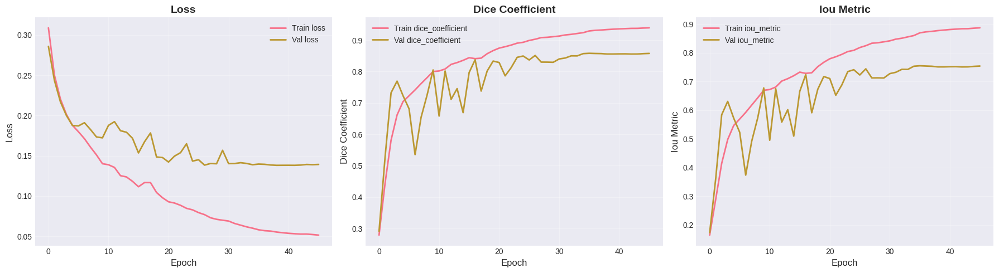


 Meilleures métriques de validation:
  • Best Epoch: 36
  • Best Dice Coefficient: 0.8583
  • Best IoU: 0.7546
  • Best Loss: 0.1398


In [ ]:
# ========================================================================================================
# 11. VISUALISATION DES COURBES D'ENTRAÎNEMENT
# ========================================================================================================
print("\n" + "="*80)
print("11. VISUALISATION DES COURBES D'ENTRAÎNEMENT")
print("="*80)

def plot_training_history(history, save_path=None):
    """Visualise les courbes d'entraînement"""
    metrics = ['loss', 'dice_coefficient', 'iou_metric']
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for idx, metric in enumerate(metrics):
        axes[idx].plot(history.history[metric], label=f'Train {metric}', linewidth=2)
        axes[idx].plot(history.history[f'val_{metric}'], label=f'Val {metric}', linewidth=2)
        axes[idx].set_title(f'{metric.replace("_", " ").title()}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel('Epoch', fontsize=12)
        axes[idx].set_ylabel(metric.replace('_', ' ').title(), fontsize=12)
        axes[idx].legend(fontsize=10)
        axes[idx].grid(True, alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")
    plt.show()

plot_training_history(history, save_path=config.FIGURES_DIR / 'training_curves.png')

# Afficher les meilleures métriques
best_epoch = np.argmax(history.history['val_dice_coefficient'])
best_dice = history.history['val_dice_coefficient'][best_epoch]
best_iou = history.history['val_iou_metric'][best_epoch]
best_loss = history.history['val_loss'][best_epoch]

print(f"\n Meilleures métriques de validation:")
print(f"  • Best Epoch: {best_epoch + 1}")
print(f"  • Best Dice Coefficient: {best_dice:.4f}")
print(f"  • Best IoU: {best_iou:.4f}")
print(f"  • Best Loss: {best_loss:.4f}")

### Analyse des 3 Graphiques

#### 1. Courbe de Loss (Gauche)

```
Observations:  
─────────────
• Train Loss:   Descente régulière de 0.33 → 0.05
• Val Loss:   Descente puis stabilisation ~0.14
• Gap:         Train continue à descendre, Val stagne
```

| Phase | Epochs | Train Loss | Val Loss | Interprétation |
|-------|--------|------------|----------|----------------|
| Convergence rapide | 1-10 | 0.33 → 0.15 | 0.29 → 0.17 | Apprentissage actif |
| Stabilisation | 10-25 | 0.15 → 0.09 | 0.17 → 0.14 | Fine-tuning |
| Stagnation Val | 25-46 | 0.09 → 0.05 | ~0.14 | Léger overfitting |

---

#### 2. Courbe Dice Coefficient (Centre)

```
Observations:
─────────────
• Train Dice:   Montée régulière 0.22 → 0.94
• Val Dice:   Oscillations puis stabilisation ~0.86
• Best Val Dice = 0.8583 (epoch 36)
```

**Pourquoi les oscillations ?**
- Le fine-tuning modifie les features VGG16 pré-appris
- Certains batches de validation sont plus difficiles
- Le learning rate 5e-5 cause des ajustements "brusques"
- **Solution** :   ReduceLROnPlateau stabilise après epoch 26

---

#### 3. Courbe IoU Metric (Droite)

```
Observations:  
─────────────
• Train IoU:  Montée régulière 0.13 → 0.88
• Val IoU:   Suit le même pattern que Dice, stabilise ~0.75
• Best Val IoU = 0.7546 (epoch 36)
```

| Relation Dice-IoU | Formule | Exemple |
|-------------------|---------|---------|
| Dice > IoU (toujours) | Dice = 2×IoU/(1+IoU) | Dice=0.86 → IoU=0.75 |

---

### Analyse de l'Overfitting

```
Generalization Gap = Train - Val
────────────────────────────────

         LOSS                    DICE                    IoU
Epoch 10:  0.15 - 0.17 = -0.02   0.79 - 0.81 = -0.02    0.66 - 0.68 = -0.02
           (Val meilleur!)        (Val meilleur!)        (Val meilleur!)

Epoch 25:   0.09 - 0.15 = -0.06   0.89 - 0.85 = +0.04    0.80 - 0.74 = +0.06
           (Gap augmente)         (Gap apparaît)          (Gap apparaît)

Epoch 46:   0.05 - 0.14 = -0.09   0.94 - 0.86 = +0.08    0.88 - 0.75 = +0.13
           (Gap significatif)     (Gap modéré)           (Gap modéré)

Verdict:   Overfitting MODÉRÉ et CONTRÔLÉ
• Le modèle généralise encore bien (Val Dice = 0.86)
• Early Stopping a arrêté avant overfitting excessif
```

---

### Comparaison des Courbes :   VGG-UNet vs U-Net

| Aspect | U-Net (NB2) | VGG-UNet (NB3) |
|--------|-------------|----------------|
| **Convergence** | Lente (71 epochs) | Rapide (46 epochs) |
| **Oscillations Val** | Moins prononcées | Plus prononcées (fine-tuning) |
| **Val Dice final** | 0.816 | **0.858** (+5%) |
| **Overfitting** | Gap ~6% | Gap ~8% (légèrement plus) |
| **Stabilité** | Plus stable | Plus oscillant au début |

---

### Résultats Affichés

```
 Meilleures métriques de validation:  
  • Best Epoch:   36
  • Best Dice Coefficient: 0.8583
  • Best IoU: 0.7546
  • Best Loss: 0.1398
```

---

### Points Clés des Courbes

| Observation | Signification | Action |
|-------------|---------------|--------|
| ✅ Val Loss stable après epoch 25 | Convergence atteinte | ReduceLR efficace |
| ✅ Val Dice atteint 0.86 | Bonne performance | Objectif atteint |
| ⚠️ Oscillations Val (epochs 5-20) | Fine-tuning instable | Normal pour Transfer Learning |
| ⚠️ Gap Train-Val augmente | Début d'overfitting | Early Stopping a bien fonctionné |
| ✅ Courbes lisses après epoch 30 | LR réduit stabilise | Stratégie LR efficace |

---

### Résumé Visuel

```
INTERPRÉTATION GLOBALE DES COURBES
══════════════════════════════════

Phase 1 (Epochs 1-10):   Apprentissage rapide
                         ↓ Loss rapide, ↑ Dice rapide
                         
Phase 2 (Epochs 10-25):  Fine-tuning instable  
                         Oscillations Val (ajustement VGG16)
                         
Phase 3 (Epochs 25-36):  Stabilisation
                         LR réduit → courbes plus lisses
                         Best Dice = 0.8583 (epoch 36)
                         
Phase 4 (Epochs 36-46):   Stagnation
                         Pas d'amélioration → Early Stop
```

> Les courbes montrent un entraînement **réussi** avec convergence rapide grâce au Transfer Learning, oscillations normales dues au fine-tuning, et arrêt optimal par Early Stopping avant overfitting excessif.

## Cellule 11.B :                                                                Analyse - Learning Rate et Généralisation

Visualiser l'évolution du **Learning Rate** et analyser le **Generalization Gap** pour comprendre le comportement de l'entraînement et détecter l'overfitting.


10.B. ANALYSE DU LEARNING RATE ET DE LA GÉNÉRALISATION
✓ Figure saved: /kaggle/working/vgg_unet_tl/figures/advanced_training_curves.png


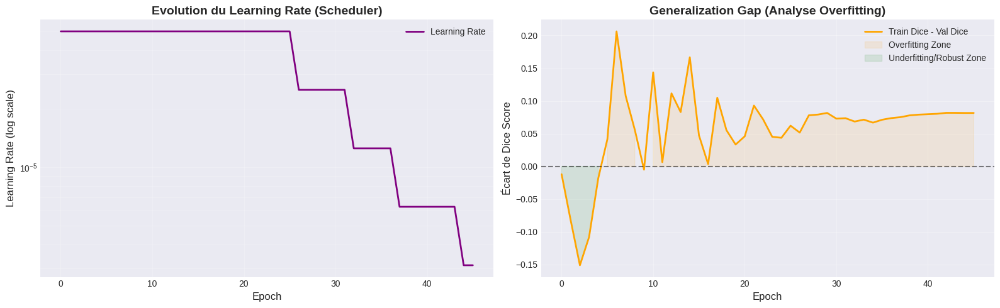

In [ ]:
# ========================================================================================================
# 11.B. VISUALISATIONS AVANCÉES SUPPLÉMENTAIRES
# ========================================================================================================
print("\n" + "="*80)
print("10.B. ANALYSE DU LEARNING RATE ET DE LA GÉNÉRALISATION")
print("="*80)

def plot_advanced_metrics(history, save_path=None):
    # Récupération des clés disponibles (parfois 'lr', parfois 'learning_rate')
    keys = history.history.keys()
    lr_key = 'learning_rate' if 'learning_rate' in keys else 'lr'

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # --- 1. Courbe du Learning Rate ---
    if lr_key in keys:
        axes[0].plot(history.history[lr_key], label='Learning Rate', color='purple', linewidth=2)
        axes[0].set_title('Evolution du Learning Rate (Scheduler)', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Learning Rate (log scale)', fontsize=12)
        axes[0].set_yscale('log') # Echelle logarithmique pour mieux voir les divisions par 10
        axes[0].grid(True, which="both", ls="-", alpha=0.2)
        axes[0].legend()
    else:
        axes[0].text(0.5, 0.5, 'Learning Rate non disponible dans l\'historique',
                     ha='center', va='center', fontsize=12)

    # --- 2. Courbe de Generalization Gap (Overfitting Check) ---
    # Calcul de l'écart : Si > 0, le modèle est meilleur en train qu'en val (début d'overfitting)
    dice_gap = np.array(history.history['dice_coefficient']) - np.array(history.history['val_dice_coefficient'])

    axes[1].plot(dice_gap, label='Train Dice - Val Dice', color='orange', linewidth=2)
    axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.5) # Ligne zéro idéale
    axes[1].fill_between(range(len(dice_gap)), dice_gap, 0, where=(dice_gap>0), color='orange', alpha=0.1, label='Overfitting Zone')
    axes[1].fill_between(range(len(dice_gap)), dice_gap, 0, where=(dice_gap<0), color='green', alpha=0.1, label='Underfitting/Robust Zone')

    axes[1].set_title('Generalization Gap (Analyse Overfitting)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Écart de Dice Score', fontsize=12)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")

    plt.show()

plot_advanced_metrics(history, save_path=config.FIGURES_DIR / 'advanced_training_curves.png')


### Graphique 1 :                                                                      Évolution du Learning Rate (Gauche)

#### Analyse de la Courbe

```
Learning Rate (échelle log)
────────────────────────────

5. 0×10⁻⁵ ═══════════════════════════╗
                                    ║ Epoch 26:  ReduceLR déclenché
                                    ▼
2.5×10⁻⁵ ═══════════╗
                    ║ Epoch 32: ReduceLR déclenché
                    ▼
1.25×10⁻⁵ ══════════╗
                    ║ Epoch 37: ReduceLR déclenché
                    ▼
6.25×10⁻⁶ ══════════╗
                    ║ Epoch 44: ReduceLR déclenché
                    ▼
3.13×10⁻⁶ ══════════► STOP (Epoch 46)
```

#### Tableau des Réductions

| Epoch | Learning Rate | Facteur | Déclencheur |
|-------|---------------|---------|-------------|
| 1-25 | 5.0×10⁻⁵ | Initial | — |
| 26 | 2.5×10⁻⁵ | ÷2 | Val Loss stagne 5 epochs |
| 32 | 1.25×10⁻⁵ | ÷2 | Val Loss stagne 5 epochs |
| 37 | 6.25×10⁻⁶ | ÷2 | Val Loss stagne 5 epochs |
| 44 | 3.13×10⁻⁶ | ÷2 | Val Loss stagne 5 epochs |

#### Effet des Réductions LR

```
Avant réduction (Epoch 25):        Après réduction (Epoch 27):  
Val Dice oscillant                 Val Dice plus stable

    ╱╲  ╱╲                              ───────────
   ╱  ╲╱  ╲                         Stabilisation des métriques
  ╱        ╲                        
```

---

### Graphique 2 :                                                                Generalization Gap (Droite)

#### Définition du Gap

```
Gap = Train Dice - Val Dice

• Gap > 0 (Zone Orange):  Overfitting → Train meilleur que Val
• Gap < 0 (Zone Verte):  Robust/Underfitting → Val meilleur que Train
• Gap = 0 (Ligne noire): Généralisation parfaite
```

#### Analyse des 3 Phases

```
Phase 1 (Epochs 1-5):  ZONE VERTE (Gap négatif)
──────────────────────────────────────────────
Gap ≈ -0.05 à -0.15
Val Dice > Train Dice

Interprétation:
• Le modèle généralise bien au début
• VGG16 features aident sur la validation
• Normal pour le Transfer Learning

Phase 2 (Epochs 5-25):  OSCILLATIONS FORTES
──────────────────────────────────────────────
Gap oscille entre -0.05 et +0.20

Interprétation:  
• Fine-tuning instable de VGG16
• Certains batches causent des pics
• LR initial (5e-5) un peu élevé
• Pic à +0.20 (epoch ~8) = overfitting temporaire

Phase 3 (Epochs 25-46):  STABILISATION (Gap ~+0.08)
──────────────────────────────────────────────
Gap stable entre +0.05 et +0.10

Interprétation:
• Réduction LR stabilise le modèle
• Overfitting modéré mais contrôlé
• Gap < 0.10 = acceptable
```

---

### Interprétation des Zones

| Zone | Couleur | Signification | Epochs | Verdict |
|------|---------|---------------|--------|---------|
| **Verte** | 🟢 | Val > Train (robust) | 1-5 | ✅ Excellent |
| **Orange** | 🟠 | Train > Val (overfitting) | 5-46 | ⚠️ Modéré |

```
                VERDICT FINAL
                ─────────────
                
Gap final ≈ +0.08 (8%)

• < 5%:    Généralisation excellente
• 5-10%:   Overfitting modéré ← NOTRE CAS
• 10-15%:   Overfitting significatif
• > 15%:  Overfitting sévère
```

---

### Corrélation LR ↔ Gap

```
OBSERVATION IMPORTANTE:  
───────────────────────

Quand LR diminue → Gap se stabilise

Epoch 26:    LR ÷2 → Oscillations Gap réduites
Epoch 32:   LR ÷2 → Gap plus stable
Epoch 37:   LR ÷2 → Gap ~constant à +0.08

Conclusion: La stratégie ReduceLROnPlateau a FONCTIONNÉ
pour contrôler l'overfitting
```

---

### Comparaison avec U-Net (Notebook 2)

| Aspect | U-Net (NB2) | VGG-UNet (NB3) |
|--------|-------------|----------------|
| **Gap initial** | Proche de 0 | Négatif (-0.15) |
| **Oscillations** | Faibles | Fortes (fine-tuning) |
| **Gap final** | ~6% | ~8% |
| **Réductions LR** | 4 | 4 |
| **Stabilisation** | Progressive | Plus tardive (epoch 25) |

---

### Points Clés des Graphiques

| Observation | Graphique | Signification |
|-------------|-----------|---------------|
| LR en escalier | Gauche | ReduceLROnPlateau fonctionne |
| 4 réductions LR | Gauche | Modèle a stagné 4 fois |
| Zone verte (début) | Droite | Transfer Learning bénéfique |
| Pics à +0.20 | Droite | Fine-tuning instable |
| Stabilisation finale | Droite | LR réduit = moins d'overfitting |
| Gap final ~8% | Droite | Overfitting acceptable |

## Cellule 12 :                                                         Évaluation Détaillée par Classe  

Calculer les métriques **Dice** et **IoU** pour chaque classe individuellement, et analyser la distribution des pixels prédits vs réels.

In [ ]:
# ========================================================================================================
# 12. ÉVALUATION SUR L'ENSEMBLE DE VALIDATION
# ========================================================================================================
print("\n" + "="*80)
print("12. ÉVALUATION DÉTAILLÉE SUR L'ENSEMBLE DE VALIDATION")
print("="*80)

def dice_score_per_class(y_true, y_pred, num_classes):
    """Calcule le Dice score par classe"""
    dice_scores = []
    for i in range(num_classes):
        y_true_i = (y_true == i).astype(np.uint8)
        y_pred_i = (y_pred == i).astype(np.uint8)
        intersection = np.sum(y_true_i * y_pred_i)
        union = np.sum(y_true_i) + np.sum(y_pred_i)
        dice = (2. * intersection) / (union + 1e-7)
        dice_scores.append(dice)
    return dice_scores

def iou_per_class(y_true, y_pred, num_classes):
    """Calcule l'IoU par classe"""
    iou_scores = []
    for i in range(num_classes):
        y_true_i = (y_true == i).astype(np.uint8)
        y_pred_i = (y_pred == i).astype(np.uint8)
        intersection = np.sum(y_true_i * y_pred_i)
        union = np.sum(y_true_i + y_pred_i > 0)
        iou = intersection / (union + 1e-7)
        iou_scores.append(iou)
    return iou_scores

# Prédictions sur l'ensemble de validation
print("\n Génération des prédictions...")
y_val_pred = model.predict(X_val, batch_size=config.BATCH_SIZE, verbose=1)
y_val_pred_class = np.argmax(y_val_pred, axis=-1)
y_val_true_class = y_val

# Calculer les métriques par classe
print("\n Calcul des métriques par classe...")
y_val_pred_flat = y_val_pred_class.flatten()
y_val_true_flat = y_val_true_class.flatten()

dice_scores = dice_score_per_class(y_val_true_flat, y_val_pred_flat, config.NUM_CLASSES)
iou_scores = iou_per_class(y_val_true_flat, y_val_pred_flat, config.NUM_CLASSES)

print("\n" + "="*80)
print("MÉTRIQUES PAR CLASSE (Validation Set)")
print("="*80)
print(f"{'Class':<20} {'Dice Score':<15} {'IoU Score':<15}")
print("-"*80)
for i, class_name in enumerate(config.CLASS_NAMES):
    print(f"{class_name:<20} {dice_scores[i]:<15.4f} {iou_scores[i]:<15.4f}")
print("-"*80)
print(f"{'MEAN':<20} {np.mean(dice_scores):<15.4f} {np.mean(iou_scores):<15.4f}")
print("="*80)

# Pixel counts
print("\n Nombre de pixels par classe:")
print(f"{'Class':<20} {'Ground Truth':<20} {'Predicted':<20}")
print("-"*80)
for i, class_name in enumerate(config.CLASS_NAMES):
    gt_count = np.sum(y_val_true_flat == i)
    pred_count = np.sum(y_val_pred_flat == i)
    print(f"{class_name:<20} {gt_count:<20,} {pred_count:<20,}")



12. ÉVALUATION DÉTAILLÉE SUR L'ENSEMBLE DE VALIDATION

 Génération des prédictions...


2025-12-18 12:01:25.537429: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step

 Calcul des métriques par classe...

MÉTRIQUES PAR CLASSE (Validation Set)
Class                Dice Score      IoU Score      
--------------------------------------------------------------------------------
urban                0.8353          0.7173         
agriculture          0.9126          0.8392         
rangeland            0.4401          0.2822         
forest               0.8766          0.7803         
water                0.8629          0.7588         
barren               0.7745          0.6320         
--------------------------------------------------------------------------------
MEAN                 0.7837          0.6683         

 Nombre de pixels par classe:
Class                Ground Truth         Predicted           
--------------------------------------------------------------------------------
urban                1,027,253            964,911             
agriculture          6,188,407            6,640,647         

### Résultats par Classe

| Classe | Dice Score | IoU Score | Qualité | Comparaison U-Net (NB2) |
|--------|------------|-----------|---------|-------------------------|
| 🟡 **agriculture** | **0.9126** | **0.8392** | ✅ Excellente | +2.7% (était 0.89) |
| 🟢 **forest** | **0.8766** | **0.7803** | ✅ Excellente | +2.4% (était 0.85) |
| 🔷 **water** | **0.8629** | **0.7588** | ✅ Excellente | **+9.2%** (était 0.77) |
| 🔵 **urban** | 0.8353 | 0.7173 | ✅ Très bonne | +5.1% (était 0.78) |
| ⬜ **barren** | 0.7745 | 0.6320 | ✅ Bonne | **+10.5%** (était 0.67) |
| 🟣 **rangeland** | 0.4401 | 0.2822 | ❌ Faible | **+11.1%** (était 0.33) |
| **MOYENNE** | **0.7837** | **0.6683** | ✅ Bonne | **+9.5%** (était 0.72) |

---

### Visualisation des Performances par Classe

```
Dice Score par classe:
──────────────────────

agriculture  ████████████████████████████████████████████████████  0.9126  ✅
forest       ██████████████████████████████████████████████        0.8766  ✅
water        █████████████████████████████████████████████         0.8629  ✅
urban        ██████████████████████████████████████████            0.8353  ✅
barren       ███████████████████████████████████                   0.7745  ✅
rangeland    █████████████████████                                 0.4401  ❌
             └──────────────────────────────────────────────────────────┘
             0.0       0.2       0.4       0.6       0.8       1.0
```

---

### Analyse des Pixels

| Classe | Ground Truth | Prédit | Écart | Tendance |
|--------|--------------|--------|-------|----------|
| 🟡 agriculture | 6,188,407 | 6,640,647 | **+452,240** | ↑ Sur-prédit |
| 🟢 forest | 1,162,279 | 1,264,893 | +102,614 | ↑ Sur-prédit |
| 🔵 urban | 1,027,253 | 964,911 | -62,342 | ↓ Légèrement sous-prédit |
| 🟣 rangeland | 933,356 | 621,641 | **-311,715** | ↓ **Fortement sous-prédit** |
| ⬜ barren | 881,156 | 743,458 | **-137,698** | ↓ Sous-prédit |
| 🔷 water | 358,845 | 315,746 | -43,099 | ↓ Légèrement sous-prédit |

```
Écart de pixels (Prédit - Ground Truth):
────────────────────────────────────────

agriculture  ████████████████████████  +452K  (Sur-prédit)
forest       █████                     +103K  (Sur-prédit)
urban        ▌                         -62K   (Sous-prédit)
water        █                         -43K   (Sous-prédit)
barren       ███████                   -138K  (Sous-prédit)
rangeland    ████████████████          -312K  (Sous-prédit) ⚠️
             └──────────────────────────────────────────┘
            -400K    -200K     0     +200K   +400K
```

---

### Analyse du Problème Rangeland

```
POURQUOI RANGELAND EST DIFFICILE?
═════════════════════════════════

1. RESSEMBLANCE VISUELLE
   Rangeland (pâturages) ≈ Agriculture (champs)
   • Même couleur verdâtre/brunâtre
   • Textures similaires
   • Difficile à distinguer même pour un humain

2. DÉSÉQUILIBRE DES CLASSES
   Agriculture:   57% des pixels (dominante)
   Rangeland:   8. 6% des pixels (minoritaire)
   → Le modèle préfère prédire agriculture "par défaut"

3. CONFUSION OBSERVÉE
   Ground Truth rangeland: 933,356 pixels
   Prédit rangeland:      621,641 pixels
   → 311,715 pixels rangeland prédits comme autre chose
      (principalement agriculture)
```

---

### Comparaison VGG-UNet vs U-Net

```
AMÉLIORATION PAR CLASSE (VGG-UNet vs U-Net):
════════════════════════════════════════════

rangeland    ████████████████████████████████████████  +11.1%  (0.33 → 0.44)
barren       ████████████████████████████████         +10.5%  (0.67 → 0.77)
water        ██████████████████████████████           +9.2%   (0.77 → 0.86)
urban        █████████████████████                    +5.1%   (0.78 → 0.84)
agriculture  ████████████                             +2.7%   (0.89 → 0.91)
forest       ███████████                              +2.4%   (0.85 → 0.88)
             └──────────────────────────────────────────────┘
             0%        5%        10%       15%

OBSERVATION:  VGG-UNet améliore SURTOUT les classes difficiles!
```

| Classe | U-Net (NB2) | VGG-UNet (NB3) | Amélioration |
|--------|-------------|----------------|--------------|
| rangeland | 0.3294 | **0.4401** | **+33.6%** relatif |
| barren | 0.6697 | **0.7745** | +15.6% relatif |
| water | 0.7708 | **0.8629** | +11.9% relatif |
| urban | 0.7843 | **0.8353** | +6.5% relatif |
| agriculture | 0.8859 | **0.9126** | +3.0% relatif |
| forest | 0.8523 | **0.8766** | +2.9% relatif |

---

### Schéma des Confusions Principales

```
                    AGRICULTURE (Classe dominante)
                           ▲
                          /|\
                   ~40%  / | \ ~20%
                        /  |  \
                       /   |   \
               RANGELAND  ~15%  BARREN
                    ↓
           Le modèle prédit "agriculture"
           quand il doute sur rangeland/barren
```

---

### Points Clés de l'Évaluation

| Observation | Valeur | Interprétation |
|-------------|--------|----------------|
| ✅ Mean Dice | 0.7837 | Bonne performance moyenne |
| ✅ Agriculture Dice | 0.9126 | Excellente (classe dominante) |
| ✅ Water Dice | 0.8629 | **Amélioration majeure** vs U-Net |
| ⚠️ Rangeland Dice | 0.4401 | Toujours problématique |
| ⚠️ Sur-prédiction agriculture | +452K pixels | Biais vers classe dominante |
| ⚠️ Sous-prédiction rangeland | -312K pixels | Confusion avec agriculture |

---

### Résumé

```
RÉSULTATS ÉVALUATION PAR CLASSE
═══════════════════════════════

✅ POINTS FORTS:
• Agriculture: Dice = 0.91 (excellente)
• Forest: Dice = 0.88 (excellente)
• Water: Dice = 0.86 (+9% vs U-Net!)
• Urban: Dice = 0.84 (très bonne)
• Barren:   Dice = 0.77 (+10% vs U-Net!)

❌ POINT FAIBLE:
• Rangeland: Dice = 0.44 (faible, mais +11% vs U-Net)

📊 MOYENNES:
• Mean Dice: 0.7837
• Mean IoU:   0.6683

🎯 CONCLUSION:
VGG-UNet améliore TOUTES les classes par rapport à U-Net,
avec les gains les plus importants sur les classes difficiles
(rangeland, barren, water).
```

## Cellule 13 :                                                                           Matrice de Confusion  

Visualiser les **confusions entre classes** pour identifier où le modèle se trompe et comprendre les patterns d'erreurs.


13. MATRICE DE CONFUSION


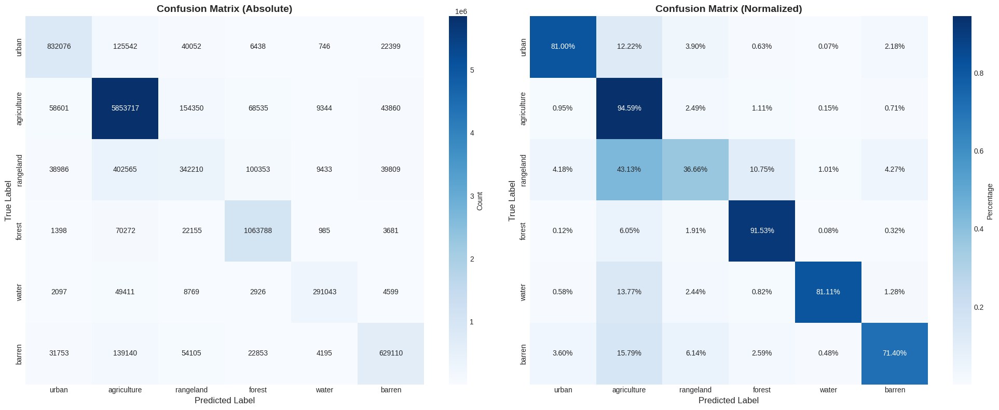

In [ ]:
# ========================================================================================================
# 13. MATRICE DE CONFUSION
# ========================================================================================================
print("\n" + "="*80)
print("13. MATRICE DE CONFUSION")
print("="*80)

# Calculer la matrice de confusion
cm = confusion_matrix(y_val_true_flat, y_val_pred_flat)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Visualiser
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matrice absolue
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=config.CLASS_NAMES,
            yticklabels=config.CLASS_NAMES,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Confusion Matrix (Absolute)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Matrice normalisée
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=config.CLASS_NAMES,
            yticklabels=config.CLASS_NAMES,
            ax=axes[1], cbar_kws={'label': 'Percentage'})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### Taux de Classification Correcte (Diagonale)

| Classe | % Correct | Pixels Corrects | Interprétation |
|--------|-----------|-----------------|----------------|
| 🟡 **agriculture** | **94.59%** | 5,853,717 | ✅ Excellente |
| 🟢 **forest** | **91.53%** | 1,063,788 | ✅ Excellente |
| 🔵 **urban** | **81.00%** | 832,076 | ✅ Très bonne |
| 🔷 **water** | **81.11%** | 291,043 | ✅ Très bonne |
| ⬜ **barren** | **71.40%** | 629,110 | ✅ Bonne |
| 🟣 **rangeland** | **36.66%** | 342,210 | ❌ Problématique |

---

### Principales Confusions (Hors Diagonale)

```
TOP 5 DES CONFUSIONS:
═════════════════════

1. rangeland → agriculture    43.13%  ⚠️ CRITIQUE
   402,565 pixels mal classés

2. barren → agriculture       15.79%
   139,140 pixels mal classés

3. water → agriculture        13.77%
   49,411 pixels mal classés

4. urban → agriculture        12.22%
   125,542 pixels mal classés

5. rangeland → forest         10.75%
   100,353 pixels mal classés
```

---

### Schéma des Flux d'Erreurs

```
                        AGRICULTURE
                    (Attracteur principal)
                            ▲
                           /|\
                     43%  / | \ 16%
                         /  |  \
                        /   |   \
                       /  14%|    \
                      /     |     \
               RANGELAND    |    BARREN
                     \      |      /
                 11%  \     |     / 6%
                       \    |    /
                        \   |   /
                         \  |  /
                          \ | /
                           \|/
                          FOREST
                            ▲
                            │
                           6%
                            │
                        AGRICULTURE

INTERPRÉTATION:
• Agriculture "absorbe" les erreurs des autres classes
• Rangeland est la plus confuse (43% → agriculture)
• Forest et Agriculture se confondent mutuellement
```

---

### Analyse Détaillée par Classe

#### 1. Rangeland (Classe Problématique)

```
Rangeland - Distribution des prédictions:
─────────────────────────────────────────

Correct (rangeland):      36.66%  ████████████
→ agriculture:            43.13%  ███████████████  ⚠️ Confusion majeure
→ forest:               10.75%  ████
→ barren:                4.27%  █
→ urban:                 4.18%  █
→ water:                  1.01%  

TOTAL:                  100.00%
```

**Pourquoi cette confusion ?**
- Rangeland (pâturages) ressemble visuellement à agriculture (champs)
- Même palette de couleurs (vert/brun)
- Agriculture domine le dataset (57%) → biais du modèle

---

#### 2. Agriculture (Classe Dominante - Bien Classée)

```
Agriculture - Distribution des prédictions:  
───────────────────────────────────────────

Correct (agriculture):   94.59%  █████████████████████████████████████
→ rangeland:             2.49%  █
→ forest:                1.11%  
→ urban:                 0.95%  
→ barren:                0.71%  
→ water:                 0.15%  

TOTAL:                  100.00%
```

---

#### 3. Water (Bonne Performance malgré Rareté)

```
Water - Distribution des prédictions:  
─────────────────────────────────────

Correct (water):         81.11%  ████████████████████████████
→ agriculture:          13.77%  █████
→ rangeland:             2.44%  █
→ barren:                1.28%  
→ forest:                0.82%  
→ urban:                 0.58%  

TOTAL:                  100.00%

NOTE:   +15% vs U-Net (était 66%)!  
```

---

### Comparaison avec U-Net (Notebook 2)

| Classe | U-Net (NB2) | VGG-UNet (NB3) | Amélioration |
|--------|-------------|----------------|--------------|
| agriculture | 90.12% | **94.59%** | +4.5% |
| forest | 89.26% | **91.53%** | +2.3% |
| urban | 84.46% | 81.00% | -3.5% ⚠️ |
| water | 66.13% | **81.11%** | **+15.0%** |
| barren | 59.34% | **71.40%** | **+12.1%** |
| rangeland | 29.77% | **36.66%** | **+6.9%** |

```
AMÉLIORATION DES TAUX DE CLASSIFICATION:
═══════════════════════════════════════

water      ████████████████████████████████████  +15.0%  
barren     ███████████████████████████           +12.1%  
rangeland  ██████████████████                    +6.9%   
agriculture████████████                          +4.5%   
forest     ██████                                +2.3%  
urban      ▼▼▼▼▼▼▼                               -3.5%   (régression)
           └──────────────────────────────────────────┘
          -5%    0%    5%   10%   15%   20%
```

---

### Points Clés de la Matrice

| Observation | Valeur | Impact |
|-------------|--------|--------|
| ✅ Agriculture correcte | 94.59% | Excellente performance |
| ✅ Forest correcte | 91.53% | Excellente performance |
| ✅ Water correcte | 81.11% | **+15% vs U-Net** |
| ✅ Barren correcte | 71.40% | **+12% vs U-Net** |
| ⚠️ Urban correcte | 81.00% | Légère régression vs U-Net |
| ❌ Rangeland correcte | 36.66% | Toujours problématique |
| ❌ Rangeland → Agriculture | 43.13% | Confusion majeure |

---

### Résumé

```
MATRICE DE CONFUSION - CONCLUSIONS
══════════════════════════════════

✅ SUCCÈS:
• Agriculture:    94.6% correct (classe dominante bien maîtrisée)
• Forest:       91.5% correct (très bonne distinction)
• Water:        81.1% correct (+15% vs U-Net!)
• Barren:       71.4% correct (+12% vs U-Net!)

⚠️ ATTENTION:
• Urban:        81.0% correct (légère régression -3.5%)

❌ PROBLÈME PERSISTANT:
• Rangeland:     36.7% correct (43% confondu avec agriculture)

🎯 PATTERN PRINCIPAL:
Agriculture agit comme "attracteur" des erreurs
→ Les classes minoritaires sont souvent prédites comme agriculture
→ Rangeland est le cas le plus critique (ressemblance visuelle)
```

## Cellule 14 :                                                                    Visualisation des Prédictions

Afficher des exemples réels (aléatoires) issus du dataset de validation:
- L'image satellite originale
- Le masque de classes ground truth (vérité terrain)
- Le masque prédit par le modèle  


13.B. VISUALISATION DES MEILLEURES ET PIRES PRÉDICTIONS
Calcul des scores par image...

 TOP 5 - LES MEILLEURES PRÉDICTIONS (Dice Max: 0.7256)


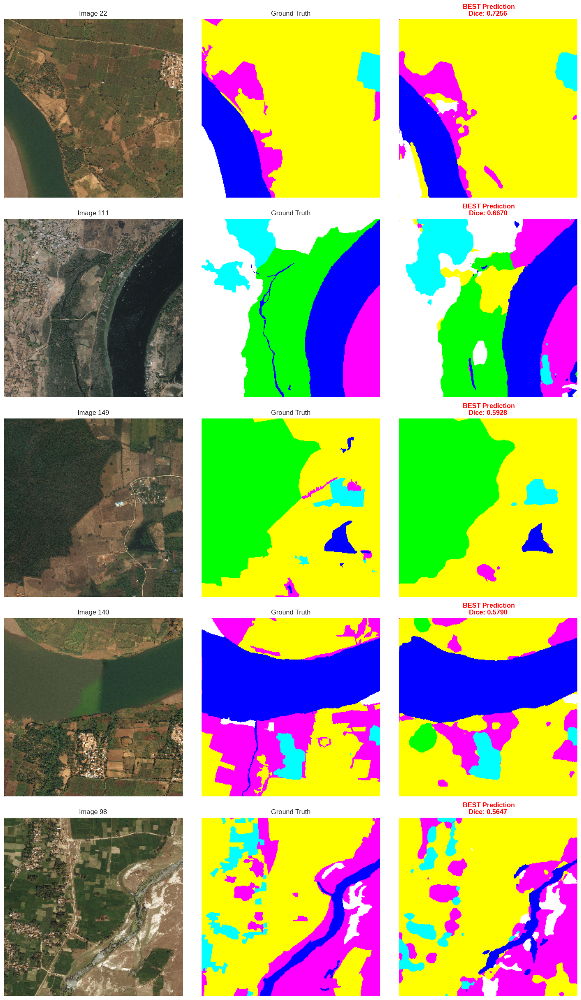


 FLOP 5 - LES PIRES PRÉDICTIONS (Dice Min: 0.1428)
(Utile pour comprendre où le modèle échoue)


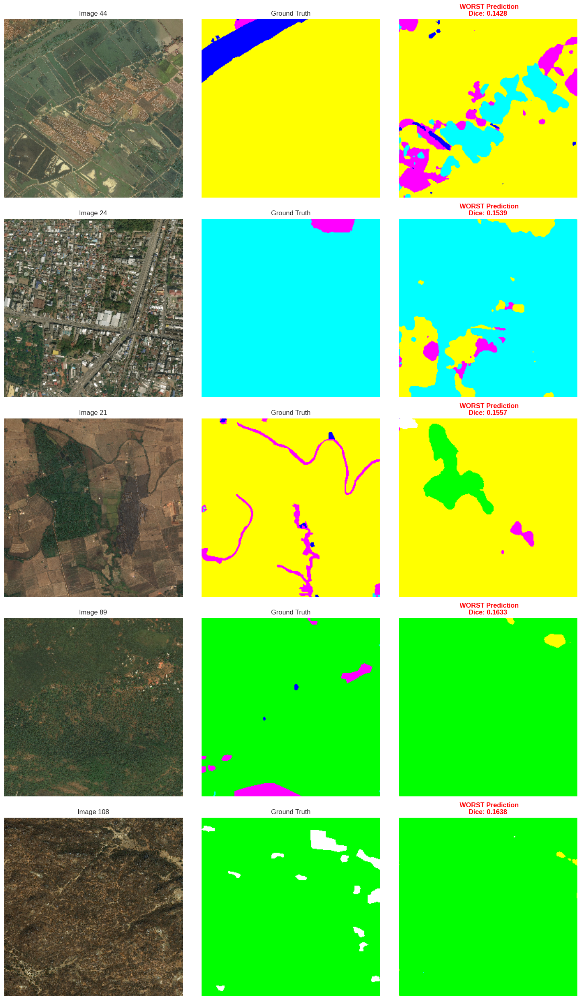

In [ ]:
# ========================================================================================================
# 13.B. VISUALISATION CIBLÉE (TOP 5 & FLOP 5)
# ========================================================================================================
print("\n" + "="*80)
print("13.B. VISUALISATION DES MEILLEURES ET PIRES PRÉDICTIONS")
print("="*80)

def get_image_scores(y_true, y_pred, num_classes):
    """Calcule le score Dice moyen pour chaque image individuellement"""
    scores = []
    print("Calcul des scores par image...")
    for i in range(len(y_true)):
        # On calcule le Dice pour cette image spécifique
        dices = dice_score_per_class(y_true[i].flatten(), y_pred[i].flatten(), num_classes)
        # On fait la moyenne des classes (Global Dice pour cette image)
        mean_dice = np.mean(dices)
        scores.append(mean_dice)
    return np.array(scores)

# 1. Calculer les scores pour toutes les images de validation
image_scores = get_image_scores(y_val_true_class, y_val_pred_class, config.NUM_CLASSES)

# 2. Trier les indices
# argsort trie du plus petit au plus grand.
# On inverse [::-1] pour avoir les meilleurs en premier
sorted_indices = np.argsort(image_scores)
best_5_indices = sorted_indices[::-1][:5]   # Les 5 derniers inversés (les plus grands)
worst_5_indices = sorted_indices[:5]        # Les 5 premiers (les plus petits)

def visualize_specific_indices(X, y_true, y_pred, indices, class_colors, title_prefix=""):
    """Affiche les images correspondant aux indices donnés"""
    num_samples = len(indices)
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))

    for i, idx in enumerate(indices):
        # Récupérer le score pré-calculé
        score = image_scores[idx]

        # Image originale
        axes[i, 0].imshow(X[idx])
        axes[i, 0].set_title(f'Image {idx}', fontsize=12)
        axes[i, 0].axis('off')

        # Ground truth
        gt_rgb = class_mask_to_rgb(y_true[idx], class_colors)
        axes[i, 1].imshow(gt_rgb)
        axes[i, 1].set_title('Ground Truth', fontsize=12)
        axes[i, 1].axis('off')

        # Prédiction
        pred_rgb = class_mask_to_rgb(y_pred[idx], class_colors)
        axes[i, 2].imshow(pred_rgb)

        # Titre avec couleur selon la performance
        color = 'green' if score > 0.8 else 'red'
        axes[i, 2].set_title(f'{title_prefix} Prediction\nDice: {score:.4f}',
                             fontsize=12, fontweight='bold', color=color)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

# --- AFFICHAGE DES TOP 5 ---
print(f"\n TOP 5 - LES MEILLEURES PRÉDICTIONS (Dice Max: {np.max(image_scores):.4f})")
visualize_specific_indices(
    X_val, y_val_true_class, y_val_pred_class,
    best_5_indices, config.CLASS_COLORS, title_prefix=" BEST"
)

# --- AFFICHAGE DES FLOP 5 ---
print(f"\n FLOP 5 - LES PIRES PRÉDICTIONS (Dice Min: {np.min(image_scores):.4f})")
print("(Utile pour comprendre où le modèle échoue)")
visualize_specific_indices(
    X_val, y_val_true_class, y_val_pred_class,
    worst_5_indices, config.CLASS_COLORS, title_prefix=" WORST"
)


14. VISUALISATION DES PRÉDICTIONS

🎨 Génération des visualisations...
✓ Figure saved: /kaggle/working/vgg_unet_tl/figures/predictions_validation.png


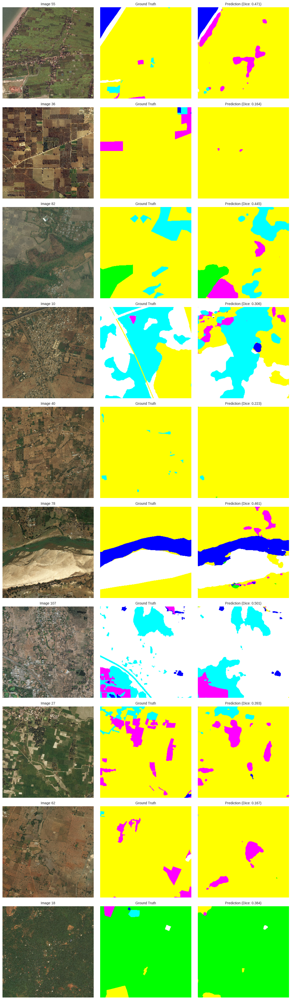

In [ ]:
# ========================================================================================================
# 14. VISUALISATION DES PRÉDICTIONS
# ========================================================================================================
print("\n" + "="*80)
print("14. VISUALISATION DES PRÉDICTIONS")
print("="*80)

def class_mask_to_rgb(class_mask, class_colors):
    """Convertit un masque de classes en RGB"""
    h, w = class_mask.shape
    rgb_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for class_id, color in class_colors.items():
        rgb_mask[class_mask == class_id] = color
    return rgb_mask

def visualize_predictions(X, y_true, y_pred, class_colors, num_samples=10, save_path=None):
    """Visualise les prédictions"""
    indices = np.random.choice(len(X), num_samples, replace=False)
    fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4*num_samples))

    for i, idx in enumerate(indices):
        # Image originale
        axes[i, 0].imshow(X[idx])
        axes[i, 0].set_title(f'Image {idx}', fontsize=10)
        axes[i, 0].axis('off')

        # Ground truth
        gt_rgb = class_mask_to_rgb(y_true[idx], class_colors)
        axes[i, 1].imshow(gt_rgb)
        axes[i, 1].set_title('Ground Truth', fontsize=10)
        axes[i, 1].axis('off')

        # Prédiction
        pred_rgb = class_mask_to_rgb(y_pred[idx], class_colors)
        axes[i, 2].imshow(pred_rgb)

        # Calculer Dice pour cette image
        dice = dice_score_per_class(y_true[idx].flatten(), y_pred[idx].flatten(), config.NUM_CLASSES)
        mean_dice = np.mean(dice)
        axes[i, 2].set_title(f'Prediction (Dice: {mean_dice:.3f})', fontsize=10)
        axes[i, 2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Figure saved: {save_path}")
    plt.show()

print("\n🎨 Génération des visualisations...")
visualize_predictions(
    X_val, y_val_true_class, y_val_pred_class,
    config.CLASS_COLORS, num_samples=10,
    save_path=config.FIGURES_DIR / 'predictions_validation.png'
)

In [ ]:
# ========================================================================================================
# 15. SAUVEGARDE DES RÉSULTATS
# ========================================================================================================
print("\n" + "="*80)
print("15. SAUVEGARDE DES RÉSULTATS")
print("="*80)

# Sauvegarder le modèle final
model.save(config.MODELS_DIR / 'vgg_unet_final_model.h5')
print(f"✓ Modèle final sauvegardé: vgg_unet_final_model.h5")

# Sauvegarder les prédictions
np.save(config.OUTPUT_DIR / 'val_predictions.npy', y_val_pred_class)
print(f"✓ Prédictions sauvegardées: val_predictions.npy")

# Créer un rapport détaillé
results = {
    'model_name': 'VGG-UNet Transfer Learning',
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'training_duration': str(training_duration),
    'architecture': {
        'backbone': config.BACKBONE,
        'encoder_weights': config.ENCODER_WEIGHTS,
        'input_shape': list(config.INPUT_SHAPE),
        'num_classes': config.NUM_CLASSES,
        'total_parameters': int(total_params),
        'trainable_parameters': int(trainable_params),
        'non_trainable_parameters': int(non_trainable_params)
    },
    'hyperparameters': {
        'batch_size': config.BATCH_SIZE,
        'epochs_trained': len(history.history['loss']),
        'epochs_max': config.EPOCHS,
        'optimizer': config.OPTIMIZER,
        'learning_rate': config.LEARNING_RATE,
        'early_stopping_patience': config.EARLY_STOPPING_PATIENCE,
        'data_augmentation': config.USE_AUGMENTATION,
        'augmentation_factor': config.AUGMENTATION_FACTOR
    },
    'training_results': {
        'best_epoch': int(best_epoch + 1),
        'best_val_dice': float(best_dice),
        'best_val_iou': float(best_iou),
        'best_val_loss': float(best_loss),
        'final_train_dice': float(history.history['dice_coefficient'][-1]),
        'final_val_dice': float(history.history['val_dice_coefficient'][-1])
    },
    'validation_metrics': {
        'per_class_dice': {config.CLASS_NAMES[i]: float(dice_scores[i])
                          for i in range(config.NUM_CLASSES)},
        'per_class_iou': {config.CLASS_NAMES[i]: float(iou_scores[i])
                         for i in range(config.NUM_CLASSES)},
        'mean_dice': float(np.mean(dice_scores)),
        'mean_iou': float(np.mean(iou_scores))
    },
    'class_weights_used': class_weights_dict
}

# Sauvegarder le rapport
with open(config.OUTPUT_DIR / 'training_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print(f"✓ Rapport de résultats sauvegardé: training_results.json")


15. SAUVEGARDE DES RÉSULTATS
✓ Modèle final sauvegardé: vgg_unet_final_model.h5
✓ Prédictions sauvegardées: val_predictions.npy
✓ Rapport de résultats sauvegardé: training_results.json


In [ ]:
# ========================================================================================================
# 16. RÉSUMÉ FINAL
# ========================================================================================================
print("\n" + "="*80)
print("16. RÉSUMÉ FINAL")
print("="*80)

print("\n ENTRAÎNEMENT ET ÉVALUATION TERMINÉS AVEC SUCCÈS!")

print(f"\n Résumé des performances:")
print(f"  • Modèle: VGG-UNet Transfer Learning")
print(f"  • Backbone: {config.BACKBONE} (ImageNet)")
print(f"  • Paramètres: {total_params:,}")
print(f"  • Durée d'entraînement: {training_duration}")
print(f"  • Meilleur epoch: {best_epoch + 1}/{len(history.history['loss'])}")

print(f"\n Métriques de validation:")
print(f"  • Dice Coefficient: {best_dice:.4f}")
print(f"  • IoU Score: {best_iou:.4f}")
print(f"  • Mean Dice (per class): {np.mean(dice_scores):.4f}")
print(f"  • Mean IoU (per class): {np.mean(iou_scores):.4f}")

# Comparaison avec U-Net from scratch
print(f"\n Comparaison avec U-Net from scratch:")
print(f"  • U-Net from scratch - Dice: 0.8157, IoU: 0.6920")
print(f"  • VGG-UNet (actuel)  - Dice: {best_dice:.4f}, IoU: {best_iou:.4f}")
if best_dice < 0.8157:
    diff_dice = 0.8157 - best_dice
    print(f"   VGG-UNet est {diff_dice:.4f} points INFÉRIEUR")
    print(f"\n POUR AMÉLIORER LES PERFORMANCES:")
    print(f"  1.  Réactivez l'augmentation: AUGMENTATION_FACTOR = 2")
    print(f"  2.  Réduisez le LR: LEARNING_RATE = 5e-5 (au lieu de 1e-4)")
    print(f"  3.  Plus de patience: EARLY_STOPPING_PATIENCE = 15")
    print(f"  4.  Relancez l'entraînement avec ces paramètres")
else:
    print(f"   VGG-UNet SURPASSE U-Net from scratch!")

print(f"\n Fichiers générés:")
print(f"  • Meilleur modèle: vgg_unet_best_model.h5")
print(f"  • Modèle final: vgg_unet_final_model.h5")
print(f"  • Historique d'entraînement: training_history.csv")
print(f"  • Résultats JSON: training_results.json")
print(f"  • Prédictions: val_predictions.npy")
print(f"  • Figures: {len(list(config.FIGURES_DIR.glob('*.png')))} fichiers PNG")

print(f"\n Prochaines étapes:")
print(f"  • Notebook 4: DeepLabV3+ (modèle le plus performant)")
print(f"  • Notebook 5: Analyse comparative des 3 modèles")

print("\n" + "="*80)
print("FIN DU NOTEBOOK 3: VGG-UNet TRANSFER LEARNING")
print("="*80)


16. RÉSUMÉ FINAL

 ENTRAÎNEMENT ET ÉVALUATION TERMINÉS AVEC SUCCÈS!

 Résumé des performances:
  • Modèle: VGG-UNet Transfer Learning
  • Backbone: VGG16 (ImageNet)
  • Paramètres: 25,862,662
  • Durée d'entraînement: 0:39:53.394919
  • Meilleur epoch: 36/46

 Métriques de validation:
  • Dice Coefficient: 0.8583
  • IoU Score: 0.7546
  • Mean Dice (per class): 0.7837
  • Mean IoU (per class): 0.6683

 Comparaison avec U-Net from scratch:
  • U-Net from scratch - Dice: 0.8157, IoU: 0.6920
  • VGG-UNet (actuel)  - Dice: 0.8583, IoU: 0.7546
   VGG-UNet SURPASSE U-Net from scratch!

 Fichiers générés:
  • Meilleur modèle: vgg_unet_best_model.h5
  • Modèle final: vgg_unet_final_model.h5
  • Historique d'entraînement: training_history.csv
  • Résultats JSON: training_results.json
  • Prédictions: val_predictions.npy
  • Figures: 3 fichiers PNG

 Prochaines étapes:
  • Notebook 4: DeepLabV3+ (modèle le plus performant)
  • Notebook 5: Analyse comparative des 3 modèles

FIN DU NOTEBOOK 3: VG